# Notes

## database version

hsapiens (Human) - version: GRCh38.p14

GO:BP – annotations: BioMart
classes: releases/2026-01-23

WP – 20260310

# Prepare

## Load Modules

In [1]:
import os

In [2]:
import numpy as np
import pandas as pd

In [3]:
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.sans-serif'] = 'Arial'
import matplotlib.pyplot as plt


In [4]:
from matplotlib.colors import LinearSegmentedColormap, Normalize

In [5]:
import gseapy as gp

In [6]:
from pygam import LinearGAM, s

In [7]:
from scipy.stats import zscore

## functions

### fit GAM

In [8]:
def add_bin_from_trajectories_score(data_df, trajectories_score_column = 'Cell_NTScore', bin_num = 100, normalization = False):
    
    if normalization:
        data_df.loc[:,trajectories_score_column] = data_df.loc[:,trajectories_score_column] / data_df.loc[:,trajectories_score_column].max()

    data_df.loc[:,'bin'] = data_df.loc[:,trajectories_score_column] * bin_num  # bin should be 0, 1, ..., bin_num - 1
    data_df.loc[:,'bin'] = data_df.loc[:,'bin'].astype(int)
    data_df.loc[data_df['bin']==bin_num,'bin'] = bin_num - 1  # remove the case of bin is bin_num

    return data_df

In [9]:
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy.ndimage import gaussian_filter1d
from pygam import LinearGAM, s

def fit_one_gene(gene, grids, y, n_splines=8):
    y_smooth = gaussian_filter1d(y, sigma=3)

    gam = LinearGAM(s(0, n_splines=n_splines))
    gam.gridsearch(
        grids,
        y_smooth,
        progress=False,
        lam=np.logspace(-3, 3, 11)
    )

    stats = gam.statistics_

    return {
        "gene": gene,
        "p_value": stats.get("p_values", [None])[0],
        "edof": stats.get("edof", None),
        "explained_deviance": stats.get("pseudo_r2", {}).get("explained_deviance", None),
        "AIC": stats.get("AIC", None),
    }


def collect_res_parallel(exp_df, n_splines=8, n_jobs=10):
    grids = exp_df.index.to_numpy().reshape(-1, 1)
    genes = exp_df.columns.to_list()

    results = Parallel(n_jobs=n_jobs, backend="loky")(
        delayed(fit_one_gene)(
            gene,
            grids,
            exp_df[gene].to_numpy(),
            n_splines
        )
        for gene in genes
    )

    return pd.DataFrame(results).set_index("gene")

In [10]:
def get_gene_filtering_metric(
    metadata_df,
    exp_df,
    trajectories_score_column = 'Cell_NTScore',
    bin_num = 100,
    trajectories_score_normalization = False,
    n_splines=8,
    n_jobs=10
):
    """
    trajectories_score_column should exist in metadata_df
    exp_df should be cell X gene
    """
    metadata_df = metadata_df[[trajectories_score_column]].copy()
    metadata_df = add_bin_from_trajectories_score(
        data_df = metadata_df,
        trajectories_score_column = trajectories_score_column,
        bin_num = bin_num,
        normalization = trajectories_score_normalization
    )

    fitGAM_input_df = exp_df.join(metadata_df['bin']).groupby('bin').mean()
    filtering_metric_df = collect_res_parallel(fitGAM_input_df, n_splines=n_splines, n_jobs=n_jobs)

    return {'filtering metric': filtering_metric_df, 'mean exp by bin': fitGAM_input_df}



### representative expression trajectories

In [11]:
def _local_maxima(distance, density, radius, genes, density_tol, distance_tol):
    """Include boundary ties; represent each equal-density peak plateau once."""
    n = len(genes)
    parent = np.arange(n)

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def union(i, j):
        a, b = find(i), find(j)
        if a != b:
            parent[b] = a

    higher_neighbor = np.zeros(n, dtype=bool)
    strict = np.ones(n, dtype=bool)
    sizes = np.zeros(n, dtype=int)
    for i in range(n):
        neighbors = np.flatnonzero(distance[i] <= radius[i] + distance_tol)
        neighbors = neighbors[neighbors != i]
        sizes[i] = len(neighbors)
        difference = density[neighbors] - density[i]
        higher_neighbor[i] = np.any(difference > density_tol)
        strict[i] = np.all(difference < -density_tol)
        for j in neighbors[np.abs(difference) <= density_tol]:
            union(i, int(j))

    groups = {}
    for i in range(n):
        groups.setdefault(find(i), []).append(i)
    is_core = np.zeros(n, dtype=bool)
    plateau_size = np.ones(n, dtype=int)
    for members in groups.values():
        plateau_size[members] = len(members)
        # Any higher-density neighbor disqualifies the entire plateau.
        if not higher_neighbor[members].any():
            representative = min(members, key=lambda i: genes[i])
            is_core[representative] = True
    return is_core, strict, plateau_size, sizes


def find_representative_expression_trajectories(
    corr_df,
    bandwidth_factor=0.30,
    bandwidth_neighbors=20,
    peak_neighbors=50,
    block_size=128,
    density_tol=1e-12,
    distance_tol=1e-12,
    qc_tol=1e-8,
    return_distance=False,
):
    """Analyze a square Pearson correlation DataFrame indexed by gene IDs.

    Parameters
    ----------
    corr_df : pandas.DataFrame
        Row/column labels must uniquely identify the same genes. Rows are
        aligned to the column order. Entirely nonfinite genes are excluded
        only when BOTH their row and column are entirely nonfinite. Other
        nonfinite entries are rejected; no imputation is performed.
    bandwidth_factor : float
        h/h0, default 0.30.
    bandwidth_neighbors : int
        Neighbor rank defining h0, default 20. h0 is ONE median distance
        across genes, computed independently for each input DataFrame.
    peak_neighbors : int
        K for the local-maximum test, default 50. This does not truncate
        the Gaussian density sum or specify the number of cores.
    return_distance : bool
        Include the distance DataFrame in the returned dictionary if True.

    Returns
    -------
    dict with keys:
        scores: all retained genes in the input column order;
        density_df: one 'density' column, indexed exactly like corr_df.index
            (all input genes in their original row order, preserving labels
            and index name); excluded all-nonfinite genes have NaN density;
        representatives: representative genes, sorted by decreasing density then gene ID;
        parameters: numerical settings, h0, h, and retained gene count;
        qc: exclusions and input validation diagnostics;
        distance: distance DataFrame, only when return_distance=True.

    Gene IDs (including any er-/tnbc- prefixes) are preserved as strings
    in existing outputs; density_df preserves the original input index.
    Density is a kernel similarity score, not a normalized probability
    density. The weight sum is not an effective sample size.
    """
    if not isinstance(corr_df, pd.DataFrame):
        raise TypeError('corr_df must be a pandas DataFrame')
    if corr_df.shape[0] != corr_df.shape[1]:
        raise ValueError('Correlation matrix must be square')
    for name, value in [('bandwidth_neighbors', bandwidth_neighbors),
                        ('peak_neighbors', peak_neighbors), ('block_size', block_size)]:
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f'{name} must be a positive integer')
    if not np.isfinite(bandwidth_factor) or bandwidth_factor <= 0:
        raise ValueError('bandwidth_factor must be finite and positive')
    if any(not np.isfinite(t) or t < 0 for t in [qc_tol, density_tol, distance_tol]):
        raise ValueError('Numerical tolerances must be finite and nonnegative')
    if corr_df.index.hasnans or corr_df.columns.hasnans:
        raise ValueError('Gene identifiers cannot be missing')
    genes = corr_df.columns.astype(str).to_numpy()
    row_genes = corr_df.index.astype(str).to_numpy()
    if (len(set(genes)) != len(genes) or len(set(row_genes)) != len(row_genes)
            or any(not g for g in genes) or set(genes) != set(row_genes)):
        raise ValueError('Row and column gene identifiers must uniquely match')
    if any(pd.api.types.is_complex_dtype(dtype) for dtype in corr_df.dtypes):
        raise ValueError('Correlations must be real numbers')
    distance = corr_df.to_numpy(dtype=np.float64, copy=True)
    reordered = not np.array_equal(row_genes, genes)
    if reordered:
        lookup = {gene: i for i, gene in enumerate(row_genes)}
        distance = distance[[lookup[g] for g in genes], :]

    # Preserve the original analysis's handling of wholly missing genes.
    all_missing = np.array([not np.isfinite(row).any() for row in distance])
    excluded = genes[all_missing].tolist()
    if all_missing.any():
        if np.isfinite(distance[:, all_missing]).any():
            raise ValueError('Entirely nonfinite rows have nonmissing columns')
        distance = distance[np.ix_(~all_missing, ~all_missing)]
        genes = genes[~all_missing]
    n = len(genes)
    if n <= max(bandwidth_neighbors, peak_neighbors):
        raise ValueError('Need more retained genes than either neighbor parameter')

    # Validate in blocks rather than allocating another full matrix.
    asymmetry, low, high = 0.0, np.inf, -np.inf
    for start in range(0, n, block_size):
        block = distance[start:start + block_size]
        if not np.isfinite(block).all():
            raise ValueError('Partial missing/nonfinite correlations; no imputation performed')
        low, high = min(low, float(block.min())), max(high, float(block.max()))
        asymmetry = max(asymmetry, float(np.max(np.abs(block - distance[:, start:start + block_size].T))))
    diagonal_error = float(np.max(np.abs(np.diag(distance) - 1)))
    if low < -1-qc_tol or high > 1+qc_tol or asymmetry > qc_tol or diagonal_error > qc_tol:
        raise ValueError('Correlation QC failed: range, symmetry or unit diagonal')
    qc = dict(status='passed', original_genes=len(corr_df), retained_genes=n,
              rows_reordered=reordered, excluded_all_nonfinite_genes=excluded,
              max_asymmetry=asymmetry, max_diagonal_error=diagonal_error,
              correlation_min=low, correlation_max=high)

    # 1. Correct only accepted numerical roundoff, then convert r to distance.
    for i in range(0, n, block_size):
        for j in range(i, n, block_size):
            mean = (distance[i:i+block_size, j:j+block_size]
                    + distance[j:j+block_size, i:i+block_size].T) * 0.5
            distance[i:i+block_size, j:j+block_size] = mean
            distance[j:j+block_size, i:i+block_size] = mean.T
    np.clip(distance, -1, 1, out=distance)
    np.fill_diagonal(distance, 1)
    np.subtract(1.0, distance, out=distance)
    distance *= 2.0
    np.sqrt(distance, out=distance)

    # 2. h0 = median distance to the 20th nearest OTHER gene; h = 0.30*h0.
    bandwidth_radius = np.empty(n)
    peak_radius = np.empty(n)
    for i in range(n):
        row = distance[i].copy()
        row[i] = np.inf
        values = np.partition(row, [bandwidth_neighbors-1, peak_neighbors-1])
        bandwidth_radius[i] = values[bandwidth_neighbors-1]
        peak_radius[i] = values[peak_neighbors-1]
    h0 = float(np.median(bandwidth_radius))
    h = float(bandwidth_factor * h0)
    if h0 <= 0 or not np.isfinite(h) or h <= 0 or h*h == 0:
        raise ValueError('Bandwidth is zero or invalid; review duplicate profiles/settings')

    # 3. Gaussian density uses ALL other genes, with self-contribution zeroed.
    density = np.empty(n)
    for start in range(0, n, block_size):
        stop = min(start + block_size, n)
        weights = np.square(distance[start:stop])
        weights *= -0.5 / h**2
        np.exp(weights, out=weights)
        weights[np.arange(stop-start), np.arange(start, stop)] = 0.0
        density[start:stop] = weights.sum(axis=1) / (n-1)

    # 4. Find peaks among the 50 nearest OTHER genes, including distance ties.
    is_core, strict, plateau_size, sizes = _local_maxima(
        distance, density, peak_radius, genes, density_tol, distance_tol)
    scores = pd.DataFrame(dict(
        gene_id=genes, density=density, weighted_neighbor_count=density*(n-1),
        is_core=is_core, strict_local_maximum=strict, plateau_size=plateau_size,
        neighborhood_size=sizes, kth_neighbor_distance=peak_radius,
    ))
    density_df = pd.DataFrame(
        {'density': pd.Series(density, index=genes).reindex(row_genes).to_numpy()},
        index=corr_df.index.copy(),
    )
    representatives = scores.loc[is_core].sort_values(
        ['density', 'gene_id'], ascending=[False, True], kind='stable').copy()
    representative_indices = representatives.index.to_numpy()
    representative_ids = representatives.gene_id.tolist()
    parameters = dict(bandwidth_factor=float(bandwidth_factor),
                      bandwidth_neighbors=int(bandwidth_neighbors),
                      peak_neighbors=int(peak_neighbors), h0=h0, h=h,
                      genes=n, core_count=len(representatives), distance='sqrt(2*(1-r))',
                      density_tol=density_tol, distance_tol=distance_tol, qc_tol=qc_tol)
    result = dict(scores=scores, density_df=density_df, representatives=representatives,
                  parameters=parameters, qc=qc)
    if return_distance:
        result['distance'] = pd.DataFrame(distance, index=genes, columns=genes)
    return result


### Ligand-Receptor

In [12]:
from collections import defaultdict
from collections.abc import Hashable, Iterable
from typing import Any, Optional

import numpy as np
import pandas as pd
from pandas.api.types import is_list_like


def _require_columns(dataframe: pd.DataFrame, columns: Iterable[str], name: str) -> None:
    """Validate that a data frame contains every requested column.

    Args:
        dataframe: Data frame whose schema is being validated.
        columns: Required column names.
        name: Human-readable input name used in the error message.

    Returns:
        None. Successful validation is indicated by the function returning
        without raising an exception.

    Raises:
        KeyError: If one or more requested columns are absent.
    """
    missing = [column for column in columns if column not in dataframe.columns]
    if missing:
        missing_text = ", ".join(repr(column) for column in missing)
        raise KeyError(f"{name} is missing required column(s): {missing_text}")


def _as_gene_list(value: Any, *, column_name: str) -> list[Hashable]:
    """Normalize one ligand or receptor definition while preserving order.

    Args:
        value: A single gene identifier, a flat list-like collection of gene
            identifiers, or a missing value.
        column_name: Source column name used in validation errors.

    Returns:
        Unique, non-missing gene identifiers in input order. Sets are sorted
        by their string representations because they have no input order.

    Raises:
        TypeError: If a gene identifier is unhashable, usually because the
            supplied collection is nested.
    """
    if value is None or (not is_list_like(value) and pd.isna(value)):
        return []

    if isinstance(value, (set, frozenset)):
        values = sorted(value, key=str)
    elif is_list_like(value) and not isinstance(value, str):
        values = value
    else:
        values = [value]

    genes: list[Hashable] = []
    seen: set[Hashable] = set()
    for gene in values:
        if gene is None or (not is_list_like(gene) and pd.isna(gene)):
            continue
        try:
            if gene not in seen:
                seen.add(gene)
                genes.append(gene)
        except TypeError as error:
            raise TypeError(
                f"Values in {column_name!r} must be gene names or flat collections "
                "of gene names."
            ) from error
    return genes


def _build_correlation_lookup(
    direction_df: pd.DataFrame,
    correlation_column_name: str,
    gene_column_name: str,
    cell_type_column_name: str,
) -> dict[Hashable, list[tuple[Hashable, float]]]:
    """Validate annotations and index cell-type correlations by gene.

    Args:
        direction_df: Pre-filtered cell-type/gene annotations.
        correlation_column_name: Column containing correlation values.
        gene_column_name: Column containing gene identifiers.
        cell_type_column_name: Column containing cell-type labels.

    Returns:
        A mapping from each gene to ordered ``(cell type, correlation)``
        records.

    Raises:
        KeyError: If a required annotation column is absent.
        TypeError: If correlation values are not numeric or identifiers are
            unhashable.
        ValueError: If identifiers or correlations are missing, correlations
            are non-finite or outside ``[-1, 1]``, or a cell-type/gene pair is
            duplicated.

    Explanation:
        A correlation belongs to a specific cell-type/gene observation. The
        uniqueness check prevents two competing values from silently producing
        ambiguous interaction scores, while grouping by gene permits efficient
        matching against large interaction catalogs.
    """
    _require_columns(
        direction_df,
        [cell_type_column_name, gene_column_name, correlation_column_name],
        "direction_df",
    )
    if direction_df[[cell_type_column_name, gene_column_name]].isna().any().any():
        raise ValueError("Cell-type labels and gene identifiers cannot contain missing values.")

    try:
        correlations = pd.to_numeric(
            direction_df[correlation_column_name], errors="raise"
        ).to_numpy(dtype=float)
    except (TypeError, ValueError) as error:
        raise TypeError(
            f"direction_df[{correlation_column_name!r}] must contain numeric values."
        ) from error

    if not np.isfinite(correlations).all():
        raise ValueError(
            f"direction_df[{correlation_column_name!r}] must contain finite, non-missing values."
        )
    if ((correlations < -1.0) | (correlations > 1.0)).any():
        raise ValueError(
            f"direction_df[{correlation_column_name!r}] values must be between -1 and 1."
        )

    lookup: defaultdict[Hashable, list[tuple[Hashable, float]]] = defaultdict(list)
    seen_pairs: set[tuple[Hashable, Hashable]] = set()
    annotations = direction_df[[cell_type_column_name, gene_column_name]].itertuples(
        index=False, name=None
    )
    for (cell_type, gene), correlation in zip(annotations, correlations):
        try:
            key = (cell_type, gene)
            if key in seen_pairs:
                raise ValueError(
                    "direction_df must contain at most one row per cell-type/gene pair; "
                    f"duplicate found for cell type {cell_type!r} and gene {gene!r}."
                )
            seen_pairs.add(key)
            lookup[gene].append((cell_type, float(correlation)))
        except TypeError as error:
            raise TypeError("Cell-type labels and gene identifiers must be hashable.") from error

    return dict(lookup)


def _calculate_concrete_lr_importance_scores(
    direction_df: pd.DataFrame,
    lr_df: pd.DataFrame,
    correlation_column_name: str = "corr_to_ME",
    gene_column_name: str = "gene",
    cell_type_column_name: str = "Cell_type",
    ligand_column_name: str = "ligand_list",
    receptor_column_name: str = "receptor_list",
) -> pd.DataFrame:
    """Calculate concrete gene-edge scores for visualization compatibility.

    Args:
        direction_df: Cell-type/gene annotations already filtered to the gene
            module and direction being analyzed.
        lr_df: Interaction definitions indexed by stable interaction IDs.
        correlation_column_name: Column in ``direction_df`` containing values
            between -1 and 1.
        gene_column_name: Column in ``direction_df`` containing gene names.
        cell_type_column_name: Column in ``direction_df`` containing cell-type
            labels.
        ligand_column_name: Column in ``lr_df`` containing ligand genes.
        receptor_column_name: Column in ``lr_df`` containing receptor genes.

    Returns:
        A long-form data frame with one row per available interaction ID,
        sender, receiver, concrete ligand gene, and concrete receptor gene.

    Raises:
        KeyError: If a required column is absent.
        TypeError: If correlations are not numeric or identifiers/gene
            definitions are invalid.
        ValueError: If correlations are invalid, a cell-type/gene annotation
            is duplicated, or ``lr_df.index`` is not unique.

    Explanation:
        Multi-gene definitions are expanded into concrete ligand-receptor
        gene pairs before their individual correlation products are scored.

        ``importance_score = ligand_corr_to_ME * receptor_corr_to_ME``

        ``absolute_importance_score = abs(importance_score)``

        The function does not select a module or correlation direction; the
        supplied ``direction_df`` defines the complete analysis scope.
    """
    _require_columns(lr_df, [ligand_column_name, receptor_column_name], "lr_df")
    if not lr_df.index.is_unique:
        raise ValueError("lr_df.index must contain unique interaction identifiers.")
    if lr_df.index.isna().any():
        raise ValueError("lr_df.index cannot contain missing interaction identifiers.")

    correlation_lookup = _build_correlation_lookup(
        direction_df,
        correlation_column_name,
        gene_column_name,
        cell_type_column_name,
    )
    columns = [
        "interaction_id",
        "sender cell type",
        "receiver cell type",
        "ligand",
        "receptor",
        "ligand_corr_to_ME",
        "receptor_corr_to_ME",
        "importance_score",
        "absolute_importance_score",
    ]
    records: list[dict[str, Any]] = []

    for interaction_id, row in lr_df.iterrows():
        ligand_genes = _as_gene_list(row[ligand_column_name], column_name=ligand_column_name)
        receptor_genes = _as_gene_list(
            row[receptor_column_name], column_name=receptor_column_name
        )
        for ligand in ligand_genes:
            for sender, ligand_correlation in correlation_lookup.get(ligand, []):
                for receptor in receptor_genes:
                    for receiver, receptor_correlation in correlation_lookup.get(receptor, []):
                        importance = ligand_correlation * receptor_correlation
                        records.append(
                            {
                                "interaction_id": interaction_id,
                                "sender cell type": sender,
                                "receiver cell type": receiver,
                                "ligand": ligand,
                                "receptor": receptor,
                                "ligand_corr_to_ME": ligand_correlation,
                                "receptor_corr_to_ME": receptor_correlation,
                                "importance_score": importance,
                                "absolute_importance_score": abs(importance),
                            }
                        )

    return pd.DataFrame.from_records(records, columns=columns)


def calculate_single_gene_lr_permutation_scores(
    direction_df: pd.DataFrame,
    lr_df: pd.DataFrame,
    n_permutations: int = 10_000,
    random_state: Optional[int] = 0,
    correlation_column_name: str = "corr_to_ME",
    gene_column_name: str = "gene",
    cell_type_column_name: str = "Cell_type",
    ligand_column_name: str = "ligand_list",
    receptor_column_name: str = "receptor_list",
    pathway_column_name: Optional[str] = "pathway_name",
) -> pd.DataFrame:
    """Score concrete LR gene pairs and estimate one-sided permutation p-values.

    Args:
        direction_df: Cell-type/gene annotations containing one correlation for
            each eligible cell-type/gene observation. All supplied genes enter
            the null pool for their cell type, including genes absent from the
            LR catalog. Filter to the intended module/direction before calling.
        lr_df: LR interaction definitions indexed by unique interaction IDs.
            Multi-gene definitions are expanded to concrete gene pairs.
        n_permutations: Number of random gene-gene correlation pairings
            generated for each sender/receiver cell-type combination.
        random_state: Seed for reproducible permutations, or ``None`` for a
            nondeterministic random generator.
        correlation_column_name: Correlation column in ``direction_df``.
        gene_column_name: Gene identifier column in ``direction_df``.
        cell_type_column_name: Cell-type column in ``direction_df``.
        ligand_column_name: Ligand definition column in ``lr_df``.
        receptor_column_name: Receptor definition column in ``lr_df``.
        pathway_column_name: Optional pathway column copied from ``lr_df`` when
            available. Set this to ``None`` to omit pathway information.

    Returns:
        A long-form data frame with one concrete ligand gene and one concrete
        receptor gene per row. It contains sender and receiver cell types, both
        input correlations, their signed product as ``importance_score``, the
        one-sided empirical ``p_value``, and optional pathway information.

    Raises:
        KeyError: If a required input column is absent.
        TypeError: If correlations, identifiers, or gene definitions are
            invalid.
        ValueError: If correlations or interaction IDs are invalid, annotations
            are duplicated, or ``n_permutations`` is not a positive integer.

    Explanation:
        Concrete observed LR edges are generated from the catalog. For each
        sender/receiver cell-type combination, the null samples one correlation
        from ALL input genes in the sender cell type and one from ALL input
        genes in the receiver cell type, independently with replacement, and
        multiplies them. Each gene contributes once to its cell type's pool;
        equal correlation values from different genes remain separate entries.
        Catalog membership and the number of LR records do not weight the pools.
        For a same-cell-type edge, both draws use the same pool and may select
        the same gene. Cell types are never pooled together.

        The upper-tail empirical p-value asks whether the observed signed
        product is larger than expected under random gene-gene pairing:

        ``p_value = (1 + count(null_score >= observed_score)) / (B + 1)``

        where ``B`` is ``n_permutations``. This tests the observed LR product
        against arbitrary gene pairs in the supplied module. All LR edges in
        one sender/receiver group share the same null distribution. It is not
        a p-value for either underlying gene correlation. Modules are not
        separated automatically; call once per module.
    """
    if (
        isinstance(n_permutations, bool)
        or not isinstance(n_permutations, int)
        or n_permutations < 1
    ):
        raise ValueError("n_permutations must be a positive integer.")

    concrete_scores = _calculate_concrete_lr_importance_scores(
        direction_df=direction_df,
        lr_df=lr_df,
        correlation_column_name=correlation_column_name,
        gene_column_name=gene_column_name,
        cell_type_column_name=cell_type_column_name,
        ligand_column_name=ligand_column_name,
        receptor_column_name=receptor_column_name,
    ).rename(
        columns={
            "ligand_corr_to_ME": "ligand_correlation",
            "receptor_corr_to_ME": "receptor_correlation",
        }
    )

    columns = [
        "interaction_id",
        "sender cell type",
        "receiver cell type",
        "ligand",
        "receptor",
        "ligand_correlation",
        "receptor_correlation",
        "importance_score",
        "p_value",
    ]
    include_pathway = (
        pathway_column_name is not None and pathway_column_name in lr_df.columns
    )
    if include_pathway:
        columns.append(pathway_column_name)
    if concrete_scores.empty:
        return pd.DataFrame(columns=columns)

    rng = np.random.default_rng(random_state)
    p_values = np.empty(len(concrete_scores), dtype=float)
    # The concrete-score helper above has already validated unique, finite
    # cell-type/gene correlations throughout direction_df.
    correlations = pd.to_numeric(direction_df[correlation_column_name]).to_numpy(
        dtype=float
    )
    gene_pools = {
        cell_type: correlations[positions]
        for cell_type, positions in direction_df.groupby(
            cell_type_column_name, sort=False, observed=True
        ).indices.items()
    }
    grouped_positions = concrete_scores.groupby(
        ["sender cell type", "receiver cell type"],
        sort=False,
        dropna=False,
    ).indices
    for (sender, receiver), positions in grouped_positions.items():
        group = concrete_scores.iloc[positions]
        null_scores = rng.choice(gene_pools[sender], size=n_permutations, replace=True) * (
            rng.choice(gene_pools[receiver], size=n_permutations, replace=True)
        )
        observed_scores = group["importance_score"].to_numpy(dtype=float)
        for position, observed_score in zip(positions, observed_scores):
            exceedances = int(np.count_nonzero(null_scores >= observed_score))
            p_values[position] = (exceedances + 1.0) / (n_permutations + 1.0)

    result = concrete_scores[
        [
            "interaction_id",
            "sender cell type",
            "receiver cell type",
            "ligand",
            "receptor",
            "ligand_correlation",
            "receptor_correlation",
            "importance_score",
        ]
    ].copy()
    result["p_value"] = p_values
    if include_pathway:
        pathway_by_interaction: dict[Any, Any] = lr_df[pathway_column_name].to_dict()
        result[pathway_column_name] = result["interaction_id"].map(
            pathway_by_interaction
        )
    return result.loc[:, columns]


## visualization

In [13]:
import hashlib
import warnings
from pathlib import Path

from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.textpath import TextPath


DEFAULT_STYLE = dict(x_rotation=45, go_column_inches=.4725)
CMAP = LinearSegmentedColormap.from_list('blue_gray_red', ['#2a78d6', '#f0efec', '#e34948'])


def validate_groups(groups):
    if not isinstance(groups, dict) or not groups:
        raise ValueError('go_terms must be a nonempty dictionary of groups.')
    for group, values in groups.items():
        if not isinstance(group, str) or not group or not isinstance(values, (list, tuple)) or not values:
            raise ValueError('Each GO group must have a name and a nonempty term list.')
        if not all(isinstance(item, str) and item.strip() for item in values):
            raise ValueError(f'GO terms must be ID strings in group {group!r}.')
        if len(values) != len(set(values)):
            raise ValueError(f'Duplicate GO term in group {group!r}.')


def read_table(path, required, numeric):
    table = pd.read_csv(path, float_precision='round_trip')
    print(f'Reading {path}...')
    missing = set(required) - set(table.columns)
    if missing:
        raise ValueError(f'{path.name}: missing columns {sorted(missing)}')
    for column in numeric:
        table[column] = pd.to_numeric(table[column], errors='raise')
        if np.isinf(table[column].to_numpy(dtype=float)).any():
            raise ValueError(f'{path.name}: infinite {column}')
    return table


def load_results(results_dir, go_terms, modules):
    """Read GSEA tables only; retain missing terms/values as unavailable cells."""
    go_rows = []
    for module in modules:
        gp = results_dir/module['gsea_file']
        go = read_table(gp, ['Term', 'NES', 'FDR q-val', 'description'], ['NES', 'FDR q-val'])
        if go.Term.isna().any() or go.Term.duplicated().any():
            raise ValueError(f'{gp.name}: Term must be present and unique.')
        if not go['FDR q-val'].dropna().between(0, 1).all():
            raise ValueError(f'{gp.name}: FDR q-val must be in [0, 1].')
        go = go.set_index('Term')
        for group, terms in go_terms.items():
            for term in terms:
                present = term in go.index
                row = go.loc[term] if present else {}
                v, q = row.get('NES', np.nan), row.get('FDR q-val', np.nan)
                description = row.get('description', term)
                if pd.isna(description) or not str(description).strip(): description = term
                go_rows.append(dict(module=module['id'], group=group, term_id=term,
                                    description=description, NES=v, FDR=q,
                                    present=present, available=bool(np.isfinite(v) and np.isfinite(q))))
    go = pd.DataFrame(go_rows)
    for key, rows in go.groupby(['group', 'term_id'], sort=False):
        if not rows.available.any(): warnings.warn(f'GO term unavailable in every module: {key}')
    return go

def go_size(q):
    return 26 if q >= .05 else 40 + 22 * min(-np.log10(max(q, 1e-30)), 20)


def column_labels(groups, data):
    labels = []
    for items in groups.values():
        for item in items:
            rows = data[data.term_id.eq(item) & data.present]
            description = str(rows.description.iloc[0]) if len(rows) else item
            labels.append(f'{description} [{item}]' if description != item else item)
    return labels


def draw_panel(ax, groups, data, modules, group_labels, style):
    columns = [(group, item) for group, items in groups.items() for item in items]
    indices = ['module', 'group', 'term_id']
    lookup = data.set_index(indices)
    for x, (group, item) in enumerate(columns):
        for y, module in enumerate(modules):
            key = (module['id'], group, item)
            row = lookup.loc[key]
            if not row.available:
                ax.text(x, y, '–', ha='center', va='center', fontsize=9, color='#888888')
            elif row.FDR >= .05:
                ax.scatter(x, y, s=go_size(row.FDR), facecolors='none', edgecolors='#b9b6b0', linewidths=.8, zorder=3)
            else:
                ax.scatter(x, y, s=go_size(row.FDR), c=[CMAP(Normalize(-5,5)(row.NES))],
                           edgecolors='black' if abs(row.NES)>5 else 'white', linewidths=.65, zorder=3)
    start = 0
    panel_inches = ax.get_position().width * ax.figure.get_figwidth()
    for group, items in groups.items():
        end = start + len(items)
        color = '#8a8a86' if group.startswith('shared') else ('#2a78d6' if group.startswith('er_') else '#e34948')
        ax.plot([start-.42,end-.58], [-.65,-.65], color=color, lw=3, clip_on=False)
        label = group_labels.get(group, group.replace('_', '\n'))
        block_width = panel_inches * len(items)/len(columns)
        fontsize = min(10, max(6, 72*block_width/(.55*max(map(len,label.splitlines())))))
        ax.text((start+end-1)/2, 1.06, label, transform=ax.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=fontsize, color=color, linespacing=1.15)
        if start: ax.axvline(start-.5, color='#d8d5cf', lw=.8)
        start = end
    for y in range(len(modules)):
        if y%2 == 0: ax.axhspan(y-.5,y+.5,color='#faf9f7',zorder=0)
        if y and modules[y]['id'].startswith('TNBC') and modules[y-1]['id'].startswith('ER'):
            ax.axhline(y-.5,color='#8a8a86',ls=(0,(4,2)),lw=1)
    ax.set(xlim=(-.6,len(columns)-.4), ylim=(len(modules)-.5,-.5),
           xticks=range(len(columns)), yticks=range(len(modules)))
    ax.set_xticklabels(column_labels(groups,data), rotation=style['x_rotation'],
                       ha='right', va='top', rotation_mode='anchor', fontsize=8.5)
    ax.set_yticklabels([m['label'] for m in modules],
                       fontsize=11,fontweight='bold')
    ax.tick_params(length=0,pad=8)
    for spine in ax.spines.values(): spine.set_visible(False)


def draw_legends(fig, left, width, height):
    x, w = left/fig.get_figwidth(), width/fig.get_figwidth()
    cax = fig.add_axes([x,2/height,w*.42,.225/height])
    fig.colorbar(ScalarMappable(norm=Normalize(-5,5),cmap=CMAP),cax=cax,
                 orientation='horizontal',ticks=[-5,0,5])
    cax.set_title('GO color: NES (clipped to ±5)',fontsize=10,pad=9)
    ax=fig.add_axes([x+w*.50,1.625/height,w*.49,1.1875/height]);ax.axis('off')
    values=[.05,1e-3,1e-6,1e-12]
    ax.set(xlim=(-.5,len(values)-.5),ylim=(-.65,1))
    for i,q in enumerate(values):
        ax.scatter(i,0,s=go_size(q),facecolors='none' if q==.05 else '#8a8a86',edgecolors='#8a8a86')
        ax.text(i,-.40,'≥0.05' if q==.05 else f'{q:g}',ha='center',fontsize=9)
    ax.text((len(values)-1)/2,.71,'GO circle area: FDR q-value',ha='center',fontsize=10)
    notes=['Hollow ring: FDR ≥ 0.05. Black outline: |NES| > 5. Dash: unavailable.',
           'Terms, groups and order follow the supplied configuration.']
    for i,note in enumerate(notes): fig.text(x,(1.0625-i*.3375)/height,note,fontsize=9)


def make_figure(go, go_terms, modules, group_labels, style):
    plt.rcParams.update({'svg.fonttype':'none','font.family':'DejaVu Sans'})
    ng = sum(map(len,go_terms.values()))
    gw = max(10,ng*style['go_column_inches'])
    left, right = 3.24, .54
    width = left+gw+right
    # Keep unusually long 45-degree labels above the legends when selections change.
    angle = np.deg2rad(style['x_rotation'])
    depth = 0
    for label in column_labels(go_terms,go):
        box = TextPath((0,0),label,size=8.5).get_extents()
        depth = max(depth,(abs(np.sin(angle))*box.width+abs(np.cos(angle))*box.height+12)/72)
    bottom = max(6.25,3.05+depth)
    matrix_height = max(2.0,len(modules)*.5729166667)
    height = bottom+matrix_height+2.8125
    fig = plt.figure(figsize=(width,height))
    ga = fig.add_axes([left/width,bottom/height,gw/width,matrix_height/height])
    draw_panel(ga,go_terms,go,modules,group_labels,style)
    ga.text(.5,1.38,'GO / pathways',transform=ga.transAxes,ha='center',fontsize=18,fontweight='bold')
    draw_legends(fig,left,gw,height)
    fig.text(left/width,1-.5/height,'Module-associated GO / pathways',fontsize=23,fontweight='bold')
    fig.text(left/width,1-1/height,f'{len(modules)} module rows · configurable groups · saved GSEA results',fontsize=12,color='#52606a')
    return fig


def plot_go_results(output_dir, go_terms, *, group_labels=None, modules=None, style=None):
    """plot based on GSEA files

    Terms, groups and modules keep their supplied order. Missing values appear
    as dashes.
    """
    validate_groups(go_terms)
    if not modules or len({m['id'] for m in modules}) != len(modules):
        raise ValueError('modules must be nonempty with unique IDs.')
    modules = [{key:m[key] for key in ['id','label','gsea_file']} for m in modules]
    unknown = set(style or {}) - set(DEFAULT_STYLE)
    if unknown: raise ValueError(f'Unknown style parameters: {sorted(unknown)}')
    style = dict(DEFAULT_STYLE, **(style or {}))
    for key in ['go_column_inches']:
        if not np.isfinite(style[key]) or style[key] <= 0: raise ValueError(f'{key} must be positive.')
    if not np.isfinite(style['x_rotation']) or not 0<=style['x_rotation']<=90:
        raise ValueError('x_rotation must be between 0 and 90.')
    group_labels = group_labels or {}
    go = load_results(Path(output_dir),go_terms,modules)
    fig = make_figure(go,go_terms,modules,group_labels,style)
    paths = {}
    fig.savefig(f'{output_dir}/Fig3D.pdf', transparent=True)
    fig.savefig(f'{output_dir}/Fig3D.svg', transparent=True)
    fig.savefig(f'{output_dir}/Fig3D.png', dpi=150)
    plt.close(fig)
    go.to_csv(f'{output_dir}/go_plot_data.csv',index=False)


In [14]:
from collections.abc import Hashable, Mapping
from typing import Any, Optional

import numpy as np
import pandas as pd


def _require_columns(
    dataframe: pd.DataFrame, columns: list[str], dataframe_name: str
) -> None:
    """Validate that a data frame contains the requested columns.

    Args:
        dataframe: Data frame whose columns are checked.
        columns: Required column names.
        dataframe_name: Human-readable input name used in errors.

    Returns:
        None. Successful validation returns without raising an exception.

    Raises:
        KeyError: If one or more requested columns are absent.
    """
    missing = [column for column in columns if column not in dataframe.columns]
    if missing:
        missing_text = ", ".join(repr(column) for column in missing)
        raise KeyError(
            f"{dataframe_name} is missing required column(s): {missing_text}"
        )


def _validate_selection_parameters(
    top_n: Optional[int],
    min_correlation: float,
    use_absolute_correlation: bool,
) -> Optional[int]:
    """Validate and normalize LR node-selection parameters.

    Args:
        top_n: Maximum number of nodes to retain for each role, or ``None``.
        min_correlation: Minimum signed or absolute correlation required.
        use_absolute_correlation: Whether filtering and ranking use magnitude.

    Returns:
        ``top_n`` normalized to a built-in integer, or ``None``.

    Raises:
        TypeError: If ``use_absolute_correlation`` is not Boolean or
            ``min_correlation`` is not numeric.
        ValueError: If ``top_n`` is invalid or the correlation threshold is
            non-finite or outside its permitted range.
    """
    if not isinstance(use_absolute_correlation, (bool, np.bool_)):
        raise TypeError("use_absolute_correlation must be a Boolean value.")
    if top_n is not None:
        if (
            isinstance(top_n, (bool, np.bool_))
            or not isinstance(top_n, (int, np.integer))
            or top_n <= 0
        ):
            raise ValueError("top_n must be a positive integer or None.")
        top_n = int(top_n)

    try:
        min_correlation = float(min_correlation)
    except (TypeError, ValueError) as error:
        raise TypeError("min_correlation must be numeric.") from error
    if not np.isfinite(min_correlation):
        raise ValueError("min_correlation must be finite.")
    lower_bound = 0.0 if use_absolute_correlation else -1.0
    if not lower_bound <= min_correlation <= 1.0:
        interval = "[0, 1]" if use_absolute_correlation else "[-1, 1]"
        raise ValueError(
            "min_correlation must be within "
            f"{interval} when use_absolute_correlation="
            f"{bool(use_absolute_correlation)}."
        )
    return top_n


def _numeric_series(
    dataframe: pd.DataFrame,
    column_name: str,
    *,
    allow_missing: bool,
) -> pd.Series:
    """Convert a column to finite floating-point values.

    Args:
        dataframe: Data frame containing the source column.
        column_name: Name of the numeric column.
        allow_missing: Whether missing values are retained as ``NaN``.

    Returns:
        A floating-point series aligned to ``dataframe.index``.

    Raises:
        TypeError: If a non-missing value is not numeric.
        ValueError: If missing values are forbidden or an infinite value is
            present.
    """
    try:
        numeric = pd.to_numeric(dataframe[column_name], errors="raise").astype(float)
    except (TypeError, ValueError) as error:
        raise TypeError(
            f"lr_df[{column_name!r}] must contain numeric values."
        ) from error
    values = numeric.to_numpy(dtype=float)
    if np.isinf(values).any():
        raise ValueError(f"lr_df[{column_name!r}] cannot contain infinite values.")
    if not allow_missing and np.isnan(values).any():
        raise ValueError(f"lr_df[{column_name!r}] cannot contain missing values.")
    return numeric


def _append_node(
    nodes_by_id: dict[tuple[str, Hashable, Hashable], dict[str, Any]],
    *,
    role: str,
    cell_type: Hashable,
    gene: Hashable,
    correlation: float,
    input_order: int,
) -> None:
    """Add one unique role/cell-type/gene node or validate its correlation.

    Args:
        nodes_by_id: Ordered node mapping being constructed.
        role: ``"ligand"`` or ``"receptor"``.
        cell_type: Sender or receiver cell-type identifier.
        gene: Gene identifier.
        correlation: Correlation assigned to this node.
        input_order: First source-row position used for stable tie-breaking.

    Returns:
        None. The mapping is updated in place when the node is new.

    Raises:
        TypeError: If the cell type or gene is not hashable.
        ValueError: If the same node has inconsistent correlation values.
    """
    try:
        node_id = (role, cell_type, gene)
        existing = nodes_by_id.get(node_id)
    except TypeError as error:
        raise TypeError("Cell-type and gene identifiers must be hashable.") from error
    if existing is None:
        nodes_by_id[node_id] = {
            "node_id": node_id,
            "role": role,
            "cell_type": cell_type,
            "gene": gene,
            "correlation": float(correlation),
            "input_order": input_order,
        }
        return
    if not np.isclose(existing["correlation"], correlation, rtol=1e-12, atol=1e-12):
        raise ValueError(
            "Each role/cell-type/gene node must have one correlation value; "
            f"conflicting values found for {node_id!r}."
        )


def _metadata_values(value: Any) -> list[Any]:
    """Normalize optional scalar or collection metadata into unique values.

    Args:
        value: Scalar, list-like collection, or missing metadata value.

    Returns:
        Unique non-missing values in deterministic input order.
    """
    is_collection = isinstance(value, (list, tuple, set, frozenset))
    if value is None or (not is_collection and pd.isna(value)):
        return []
    if isinstance(value, (set, frozenset)):
        values = sorted(value, key=str)
    elif isinstance(value, (list, tuple)):
        values = value
    else:
        values = [value]
    result: list[Any] = []
    for item in values:
        if item is None or pd.isna(item):
            continue
        if item not in result:
            result.append(item)
    return result


def select_lr_circle_data(
    lr_df: pd.DataFrame,
    top_n: Optional[int] = 20,
    min_correlation: float = 0.0,
    use_absolute_correlation: bool = False,
    max_p_value: Optional[float] = 0.05,
    sender_cell_type_column: str = "sender cell type",
    receiver_cell_type_column: str = "receiver cell type",
    ligand_column: str = "ligand",
    receptor_column: str = "receptor",
    ligand_correlation_column: str = "ligand_correlation",
    receptor_correlation_column: str = "receptor_correlation",
    importance_score_column: str = "importance_score",
    p_value_column: str = "p_value",
    interaction_id_column: Optional[str] = "interaction_id",
    pathway_column: Optional[str] = "pathway_name",
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Select ligand/receptor nodes and edges for a circular LR plot.

    Args:
        lr_df: Concrete ligand-receptor interactions. Each row connects one
            sender cell-type/ligand node to one receiver cell-type/receptor
            node.
        top_n: Maximum number of nodes retained independently for ligand and
            receptor roles. ``None`` keeps all nodes passing the threshold.
        min_correlation: Minimum selection correlation. Its valid range is
            ``[-1, 1]`` for signed filtering and ``[0, 1]`` for absolute
            filtering.
        use_absolute_correlation: If ``True``, filtering and top-N ranking use
            absolute correlation magnitude. Otherwise they use signed values.
        max_p_value: Maximum retained LR-pair p-value, inclusive. The default
            is ``0.05``; ``None`` disables p-value filtering. This filters
            edges only and never removes otherwise selected nodes.
        sender_cell_type_column: Sender cell-type column.
        receiver_cell_type_column: Receiver cell-type column.
        ligand_column: Ligand gene column.
        receptor_column: Receptor gene column.
        ligand_correlation_column: Ligand correlation column.
        receptor_correlation_column: Receptor correlation column.
        importance_score_column: LR importance score used for edge width.
        p_value_column: P-value column used for edge filtering and coloring.
        interaction_id_column: Optional interaction identifier column copied
            into aggregated edge metadata when present.
        pathway_column: Optional pathway column copied into aggregated edge
            metadata when present.
    Returns:
        A ``(nodes, edges)`` tuple. Nodes contain role-aware identifiers,
        correlations, selection values, and stable source order. Edges contain
        only interactions whose two endpoints passed node filtering and whose
        p-values passed edge filtering; duplicate endpoints are collapsed with
        their minimum p-value and ordered interaction/pathway metadata. Selected
        nodes are retained even when they have no retained edges.

    Raises:
        KeyError: If a required configured column is absent.
        TypeError: If parameters, correlations, scores, or identifiers have
            invalid types.
        ValueError: If parameters or numeric values are invalid, identifiers
            are missing, or repeated nodes/edges have conflicting scores.

    Explanation:
        Node identity is ``(role, cell type, gene)``. Role keeps a gene that
        acts as both ligand and receptor in the two appropriate semicircles;
        cell type keeps the same gene in different biological populations
        distinct. The label format selected during plotting never changes this
        identity.
    """
    top_n = _validate_selection_parameters(
        top_n, min_correlation, use_absolute_correlation
    )
    if max_p_value is not None:
        if isinstance(max_p_value, (bool, np.bool_)):
            raise TypeError("max_p_value must be numeric or None.")
        try:
            max_p_value = float(max_p_value)
        except (TypeError, ValueError) as error:
            raise TypeError("max_p_value must be numeric or None.") from error
        if not np.isfinite(max_p_value) or not 0.0 <= max_p_value <= 1.0:
            raise ValueError("max_p_value must be between 0 and 1.")
    required_columns = [
        sender_cell_type_column,
        receiver_cell_type_column,
        ligand_column,
        receptor_column,
        ligand_correlation_column,
        receptor_correlation_column,
        importance_score_column,
        p_value_column,
    ]
    _require_columns(lr_df, required_columns, "lr_df")
    p_values = _numeric_series(lr_df, p_value_column, allow_missing=True)
    finite_p_values = p_values.dropna().to_numpy(dtype=float)
    if ((finite_p_values < 0.0) | (finite_p_values > 1.0)).any():
        raise ValueError(f"lr_df[{p_value_column!r}] values must be between 0 and 1.")
    if max_p_value is None:
        edge_passes_p_value = pd.Series(True, index=lr_df.index, dtype=bool)
    else:
        edge_passes_p_value = p_values <= max_p_value
    if interaction_id_column is not None and interaction_id_column not in lr_df.columns:
        interaction_id_column = None
    if pathway_column is not None and pathway_column not in lr_df.columns:
        pathway_column = None

    identifiers = lr_df[
        [
            sender_cell_type_column,
            receiver_cell_type_column,
            ligand_column,
            receptor_column,
        ]
    ]
    if identifiers.isna().any().any():
        raise ValueError(
            "Cell-type and gene identifiers cannot contain missing values."
        )

    ligand_correlations = _numeric_series(
        lr_df, ligand_correlation_column, allow_missing=False
    )
    receptor_correlations = _numeric_series(
        lr_df, receptor_correlation_column, allow_missing=False
    )
    importance_scores = _numeric_series(
        lr_df, importance_score_column, allow_missing=True
    )
    for column_name, correlations in (
        (ligand_correlation_column, ligand_correlations),
        (receptor_correlation_column, receptor_correlations),
    ):
        values = correlations.to_numpy(dtype=float)
        if ((values < -1.0) | (values > 1.0)).any():
            raise ValueError(f"lr_df[{column_name!r}] values must be between -1 and 1.")

    nodes_by_id: dict[tuple[str, Hashable, Hashable], dict[str, Any]] = {}
    row_records: list[dict[str, Any]] = []
    for position, (_, row) in enumerate(lr_df.iterrows()):
        sender = row[sender_cell_type_column]
        receiver = row[receiver_cell_type_column]
        ligand = row[ligand_column]
        receptor = row[receptor_column]
        ligand_correlation = float(ligand_correlations.iloc[position])
        receptor_correlation = float(receptor_correlations.iloc[position])
        _append_node(
            nodes_by_id,
            role="ligand",
            cell_type=sender,
            gene=ligand,
            correlation=ligand_correlation,
            input_order=position,
        )
        _append_node(
            nodes_by_id,
            role="receptor",
            cell_type=receiver,
            gene=receptor,
            correlation=receptor_correlation,
            input_order=position,
        )
        row_records.append(
            {
                "ligand_node_id": ("ligand", sender, ligand),
                "receptor_node_id": ("receptor", receiver, receptor),
                "importance_score": float(importance_scores.iloc[position]),
                "p_value": float(p_values.iloc[position]),
                "interaction_id": (
                    row[interaction_id_column]
                    if interaction_id_column is not None
                    else None
                ),
                "pathway": row[pathway_column] if pathway_column is not None else None,
                "passes_p_value": bool(edge_passes_p_value.iloc[position]),
                "input_order": position,
            }
        )

    node_columns = [
        "node_id",
        "role",
        "cell_type",
        "gene",
        "correlation",
        "selection_correlation",
        "input_order",
    ]
    nodes = pd.DataFrame.from_records(list(nodes_by_id.values()))
    if nodes.empty:
        nodes = pd.DataFrame(columns=node_columns)
    else:
        nodes["selection_correlation"] = (
            nodes["correlation"].abs()
            if use_absolute_correlation
            else nodes["correlation"]
        )
        selected_roles: list[pd.DataFrame] = []
        for role in ("ligand", "receptor"):
            role_nodes = nodes.loc[
                (nodes["role"] == role)
                & (nodes["selection_correlation"] >= float(min_correlation))
            ].sort_values(
                ["selection_correlation", "input_order"],
                ascending=[False, True],
                kind="mergesort",
            )
            if top_n is not None:
                role_nodes = role_nodes.head(top_n)
            selected_roles.append(role_nodes)
        nodes = pd.concat(selected_roles, ignore_index=True)[node_columns]

    selected_node_ids = set(nodes["node_id"])
    edge_columns = [
        "ligand_node_id",
        "receptor_node_id",
        "importance_score",
        "p_value",
        "interaction_ids",
        "pathways",
        "input_order",
    ]
    edges_by_id: dict[
        tuple[tuple[str, Hashable, Hashable], tuple[str, Hashable, Hashable]],
        dict[str, Any],
    ] = {}
    for record in row_records:
        if not record["passes_p_value"]:
            continue
        ligand_node_id = record["ligand_node_id"]
        receptor_node_id = record["receptor_node_id"]
        if (
            ligand_node_id not in selected_node_ids
            or receptor_node_id not in selected_node_ids
        ):
            continue
        edge_id = (ligand_node_id, receptor_node_id)
        edge = edges_by_id.get(edge_id)
        if edge is None:
            edge = {
                "ligand_node_id": ligand_node_id,
                "receptor_node_id": receptor_node_id,
                "importance_score": record["importance_score"],
                "p_value": record["p_value"],
                "interaction_ids": [],
                "pathways": [],
                "input_order": record["input_order"],
            }
            edges_by_id[edge_id] = edge
        else:
            existing_score = edge["importance_score"]
            new_score = record["importance_score"]
            both_missing = pd.isna(existing_score) and pd.isna(new_score)
            both_equal = (
                not pd.isna(existing_score)
                and not pd.isna(new_score)
                and np.isclose(existing_score, new_score, rtol=1e-12, atol=1e-12)
            )
            if not (both_missing or both_equal):
                raise ValueError(
                    "Duplicate LR endpoints must have one importance score; "
                    f"conflicting values found for {edge_id!r}."
                )
            existing_p_value = edge["p_value"]
            new_p_value = record["p_value"]
            if pd.isna(existing_p_value) or (
                not pd.isna(new_p_value) and new_p_value < existing_p_value
            ):
                edge["p_value"] = new_p_value
        for interaction_id in _metadata_values(record["interaction_id"]):
            if interaction_id not in edge["interaction_ids"]:
                edge["interaction_ids"].append(interaction_id)
        for pathway in _metadata_values(record["pathway"]):
            if pathway not in edge["pathways"]:
                edge["pathways"].append(pathway)

    edges = pd.DataFrame.from_records(list(edges_by_id.values()), columns=edge_columns)
    return nodes.reset_index(drop=True), edges.reset_index(drop=True)


def _add_circle_positions(
    nodes: pd.DataFrame,
    *,
    correlation_order: str,
    radius: float,
    arc_margin_degrees: float,
) -> pd.DataFrame:
    """Assign upper/lower semicircle coordinates to selected LR nodes.

    Args:
        nodes: Selected node table from :func:`select_lr_circle_data`.
        correlation_order: ``"ascending"`` or ``"descending"`` signed order.
        radius: Circle radius.
        arc_margin_degrees: Empty angular margin at each horizontal endpoint.

    Returns:
        A copy of ``nodes`` with ``x``, ``y``, ``angle``, and ``layout_order``.

    Raises:
        ValueError: If the requested ordering or geometry is invalid.
    """
    if correlation_order not in {"ascending", "descending"}:
        raise ValueError("correlation_order must be 'ascending' or 'descending'.")
    if not np.isfinite(radius) or radius <= 0:
        raise ValueError("radius must be a positive finite number.")
    if not np.isfinite(arc_margin_degrees) or not 0 <= arc_margin_degrees < 90:
        raise ValueError("arc_margin_degrees must be within [0, 90).")

    positioned: list[pd.DataFrame] = []
    ascending = correlation_order == "ascending"
    margin = np.deg2rad(arc_margin_degrees)
    for role in ("ligand", "receptor"):
        role_nodes = (
            nodes.loc[nodes["role"] == role]
            .sort_values(
                ["correlation", "input_order"],
                ascending=[ascending, True],
                kind="mergesort",
            )
            .copy()
        )
        count = len(role_nodes)
        if count == 0:
            continue
        if count == 1:
            angles = np.array([np.pi / 2 if role == "ligand" else 3 * np.pi / 2])
        elif role == "ligand":
            angles = np.linspace(np.pi - margin, margin, count)
        else:
            angles = np.linspace(np.pi + margin, 2 * np.pi - margin, count)
        role_nodes["angle"] = angles
        role_nodes["x"] = radius * np.cos(angles)
        role_nodes["y"] = radius * np.sin(angles)
        role_nodes["layout_order"] = np.arange(count)
        positioned.append(role_nodes)
    columns = [*nodes.columns, "angle", "x", "y", "layout_order"]
    if not positioned:
        return pd.DataFrame(columns=columns)
    return pd.concat(positioned, ignore_index=True)[columns]


def _observed_range(values: np.ndarray) -> Optional[tuple[float, float]]:
    """Return the minimum and maximum finite values in an array.

    Args:
        values: Numeric values that may contain missing values.

    Returns:
        A ``(minimum, maximum)`` tuple, or ``None`` when no finite values are
        available.
    """
    finite_values = values[np.isfinite(values)]
    if finite_values.size == 0:
        return None
    return float(finite_values.min()), float(finite_values.max())


def _scale_observed_values(
    values: np.ndarray,
    observed_range: Optional[tuple[float, float]],
    output_minimum: float,
    output_maximum: float,
    *,
    missing_output: float,
) -> np.ndarray:
    """Linearly scale finite values across their observed numeric range.

    Args:
        values: Values to scale.
        observed_range: Source ``(minimum, maximum)``. ``None`` indicates that
            no finite source values are available.
        output_minimum: Output assigned to the observed minimum.
        output_maximum: Output assigned to the observed maximum.
        missing_output: Output assigned to non-finite values.

    Returns:
        Scaled values with the same shape as ``values``.

    Explanation:
        If every finite source value is identical, there is no data-supported
        size or width contrast. Those values receive the midpoint of the
        requested output range rather than being presented as either the
        smallest or largest observation.
    """
    scaled = np.full(values.shape, missing_output, dtype=float)
    finite_mask = np.isfinite(values)
    if observed_range is None or not finite_mask.any():
        return scaled
    source_minimum, source_maximum = observed_range
    if np.isclose(source_minimum, source_maximum):
        scaled[finite_mask] = (output_minimum + output_maximum) / 2.0
        return scaled
    normalized = (values[finite_mask] - source_minimum) / (
        source_maximum - source_minimum
    )
    scaled[finite_mask] = output_minimum + np.clip(normalized, 0.0, 1.0) * (
        output_maximum - output_minimum
    )
    return scaled


def _edge_widths(
    width_scores: pd.Series,
    min_edge_width: float,
    max_edge_width: float,
    observed_score_range: Optional[tuple[float, float]] = None,
) -> np.ndarray:
    """Map prepared LR importance scores to positive edge widths.

    Args:
        width_scores: Signed or absolute LR importance scores selected by the
            caller; missing values are allowed.
        min_edge_width: Width for the smallest observed finite score and
            for undefined scores.
        max_edge_width: Width for the largest observed finite score.
        observed_score_range: Optional source score range shared with
            legend examples. If omitted, it is inferred from the scores.

    Returns:
        Edge widths aligned to ``importance_scores``.

    Raises:
        ValueError: If width limits are non-finite, non-positive, or reversed.
    """
    if (
        not np.isfinite(min_edge_width)
        or not np.isfinite(max_edge_width)
        or min_edge_width <= 0
        or max_edge_width < min_edge_width
    ):
        raise ValueError(
            "Edge widths must be finite and satisfy "
            "0 < min_edge_width <= max_edge_width."
        )
    values = width_scores.to_numpy(dtype=float)
    if observed_score_range is None:
        observed_score_range = _observed_range(values)
    return _scale_observed_values(
        values,
        observed_score_range,
        min_edge_width,
        max_edge_width,
        missing_output=min_edge_width,
    )


def _negative_log10_p_values(p_values: pd.Series) -> pd.Series:
    """Transform LR p-values into non-negative edge-color scores.

    Args:
        p_values: Numeric p-values in ``[0, 1]``; missing values are allowed.

    Returns:
        A float series aligned to ``p_values`` containing ``-log10(p)``.
        Missing values remain missing. Exact zeros are clipped to the smallest
        positive normalized float before transformation.

    Explanation:
        Clipping exact zeros avoids infinite color values while preserving
        their interpretation as the strongest possible significance in the
        supplied data.
    """
    transformed = pd.Series(np.nan, index=p_values.index, dtype=float)
    finite_mask = p_values.notna()
    if finite_mask.any():
        positive_floor = np.finfo(float).tiny
        transformed.loc[finite_mask] = -np.log10(
            p_values.loc[finite_mask].clip(lower=positive_floor).to_numpy(dtype=float)
        )
    return transformed


def _pathway_key(pathways: list[Any]) -> tuple[str, ...]:
    """Create a stable categorical key for an edge's pathway metadata.

    Args:
        pathways: Ordered pathway values aggregated for one edge.

    Returns:
        A tuple of string representations. An empty tuple represents an edge
        without pathway annotation.

    Explanation:
        Duplicate ligand-receptor endpoints may aggregate multiple catalog
        rows and therefore multiple pathways. Keeping the complete ordered
        tuple gives such an edge its own explicit combined category rather
        than arbitrarily selecting one pathway.
    """
    return tuple(str(pathway) for pathway in pathways)


def _pathway_label(pathway_key: tuple[str, ...]) -> str:
    """Format a pathway category for the plot legend.

    Args:
        pathway_key: Pathway key returned by :func:`_pathway_key`.

    Returns:
        One pathway name, a slash-separated combined category, or
        ``"Unspecified"`` when the edge has no annotation.
    """
    if not pathway_key:
        return "Unspecified"
    return " / ".join(pathway_key)


def _validate_plot_range(
    value: Optional[tuple[float, float]],
    parameter_name: str,
    *,
    nonnegative: bool = False,
) -> Optional[tuple[float, float]]:
    """Validate an optional two-endpoint visualization range.

    Args:
        value: Requested lower and upper display limits, or ``None``.
        parameter_name: Parameter name used in validation errors.
        nonnegative: Whether the lower limit must be at least zero.

    Returns:
        A normalized ``(lower, upper)`` float tuple, or ``None``.

    Raises:
        TypeError: If the range is not a two-item tuple or list of numbers.
        ValueError: If limits are non-finite, reversed, equal, or negative when
            ``nonnegative`` is enabled.
    """
    if value is None:
        return None
    if not isinstance(value, (tuple, list)) or len(value) != 2:
        raise TypeError(f"{parameter_name} must be None or a two-item tuple or list.")
    if any(isinstance(limit, (bool, np.bool_)) for limit in value):
        raise TypeError(f"{parameter_name} limits must be numeric.")
    try:
        lower, upper = (float(limit) for limit in value)
    except (TypeError, ValueError) as error:
        raise TypeError(f"{parameter_name} limits must be numeric.") from error
    if not np.isfinite(lower) or not np.isfinite(upper):
        raise ValueError(f"{parameter_name} limits must be finite.")
    if lower >= upper:
        raise ValueError(f"{parameter_name} must satisfy lower limit < upper limit.")
    if nonnegative and lower < 0:
        raise ValueError(f"{parameter_name} limits must be non-negative.")
    return lower, upper


def _validate_highlight_pathways(
    highlight_pathways: Optional[list[Any] | Mapping[Any, Any]],
) -> tuple[list[str], Optional[dict[str, Any]]]:
    """Validate pathway names and optional user-specified highlight colors.

    Args:
        highlight_pathways: Pathway values in priority order, a mapping from
            pathway values to Matplotlib colors, or ``None`` to disable
            pathway-based gene highlighting.

    Returns:
        A tuple containing unique string pathway names in their original order
        and either their requested color mapping or ``None`` when colors should
        be generated automatically.

    Raises:
        TypeError: If the input is neither a list nor a mapping.
        ValueError: If a pathway name is missing, empty, or duplicated after
            string normalization.

    Explanation:
        Priority order matters when one retained gene participates in multiple
        highlighted pathways: the first matching pathway controls its label
        color.
    """
    if highlight_pathways is None:
        return [], None
    if isinstance(highlight_pathways, Mapping):
        pathway_items = list(highlight_pathways.items())
        requested_colors: Optional[dict[str, Any]] = {}
    elif isinstance(highlight_pathways, list):
        pathway_items = [(pathway, None) for pathway in highlight_pathways]
        requested_colors = None
    else:
        raise TypeError("highlight_pathways must be a list, mapping, or None.")
    normalized: list[str] = []
    for pathway, color in pathway_items:
        if pathway is None or pd.isna(pathway):
            raise ValueError("highlight_pathways cannot contain missing values.")
        pathway_name = str(pathway).strip()
        if not pathway_name:
            raise ValueError("highlight_pathways cannot contain empty names.")
        if pathway_name in normalized:
            if requested_colors is not None:
                raise ValueError(
                    "highlight_pathways contains duplicate names after string "
                    "normalization."
                )
            continue
        normalized.append(pathway_name)
        if requested_colors is not None:
            requested_colors[pathway_name] = color
    return normalized, requested_colors


def _resolve_highlight_pathway_colors(
    pathway_names: list[str],
    requested_colors: Optional[dict[str, Any]],
    colormaps: Any,
    is_color_like: Any,
) -> dict[str, Any]:
    """Resolve automatic or explicitly requested pathway highlight colors.

    Args:
        pathway_names: Validated pathway names in priority order.
        requested_colors: Explicit pathway-to-color mapping, or ``None`` to
            generate distinct categorical colors.
        colormaps: Matplotlib colormap registry.
        is_color_like: Matplotlib color-validation function.

    Returns:
        Ordered pathway-to-color mapping used for labels and the highlight
        legend.

    Raises:
        ValueError: If an explicitly requested color is not understood by
            Matplotlib.
    """
    if requested_colors is not None:
        for pathway, color in requested_colors.items():
            if not is_color_like(color):
                raise ValueError(
                    f"highlight_pathways color for {pathway!r} must be a valid "
                    "Matplotlib color."
                )
        return dict(requested_colors)
    highlight_color_map = colormaps[
        (
            "tab10"
            if len(pathway_names) <= 10
            else "tab20" if len(pathway_names) <= 20 else "hsv"
        )
    ]
    highlight_color_values = highlight_color_map(
        np.linspace(0.0, 1.0, max(1, len(pathway_names)), endpoint=False)
    )
    return dict(zip(pathway_names, highlight_color_values))


def _highlighted_node_annotations(
    lr_df: pd.DataFrame,
    selected_nodes: pd.DataFrame,
    pathway_colors: dict[str, Any],
    *,
    sender_cell_type_column: str,
    receiver_cell_type_column: str,
    ligand_column: str,
    receptor_column: str,
    pathway_column: str,
) -> tuple[
    dict[tuple[str, Hashable, Hashable], Any],
    list[str],
    dict[Hashable, list[str]],
]:
    """Map selected source-table nodes to pathway highlight colors.

    Args:
        lr_df: Original LR table before edge p-value and endpoint filtering.
        selected_nodes: Nodes retained by correlation and top-N selection.
        pathway_colors: Ordered mapping from selected pathway names to colors.
        sender_cell_type_column: Sender cell-type column.
        receiver_cell_type_column: Receiver cell-type column.
        ligand_column: Ligand gene column.
        receptor_column: Receptor gene column.
        pathway_column: Pathway metadata column.

    Returns:
        A tuple containing the role-aware node-to-color mapping, pathway names
        that contributed at least one visible colored node, and a
        ``{gene: [pathway, ...]}`` mapping for selected genes assigned to
        multiple highlighted pathways.

    Explanation:
        Highlight membership is evaluated against the full input table, not
        only retained edges. A selected node can therefore be highlighted even
        when its counterpart fails node selection or the LR pair fails the
        p-value cutoff. The pathway-color mapping preserves user priority;
        the first pathway assigning a node controls its single label color.
    """
    selected_node_ids = set(selected_nodes["node_id"])
    memberships = {node_id: [] for node_id in selected_node_ids}
    highlighted_pathway_names = set(pathway_colors)
    for _, row in lr_df.iterrows():
        row_pathways = [
            str(value)
            for value in _metadata_values(row[pathway_column])
            if str(value) in highlighted_pathway_names
        ]
        if not row_pathways:
            continue
        endpoint_ids = (
            (
                "ligand",
                row[sender_cell_type_column],
                row[ligand_column],
            ),
            (
                "receptor",
                row[receiver_cell_type_column],
                row[receptor_column],
            ),
        )
        for node_id in endpoint_ids:
            if node_id not in memberships:
                continue
            for pathway in row_pathways:
                if pathway not in memberships[node_id]:
                    memberships[node_id].append(pathway)

    node_colors: dict[tuple[str, Hashable, Hashable], Any] = {}
    assigned_pathways: set[str] = set()
    multiple_pathway_genes: dict[Hashable, list[str]] = {}
    selected_by_id = {
        node.node_id: node for node in selected_nodes.itertuples(index=False)
    }
    for node_id in selected_nodes["node_id"]:
        ordered_pathways = tuple(
            pathway for pathway in pathway_colors if pathway in memberships[node_id]
        )
        if not ordered_pathways:
            continue
        assigned_pathway = ordered_pathways[0]
        node_colors[node_id] = pathway_colors[assigned_pathway]
        assigned_pathways.add(assigned_pathway)
        if len(ordered_pathways) < 2:
            continue
        node = selected_by_id[node_id]
        gene_pathways = multiple_pathway_genes.setdefault(node.gene, [])
        for pathway in ordered_pathways:
            if pathway not in gene_pathways:
                gene_pathways.append(pathway)
    active_pathways = [
        pathway for pathway in pathway_colors if pathway in assigned_pathways
    ]
    return node_colors, active_pathways, multiple_pathway_genes


def _add_stacked_legend(
    figure: Any,
    legend_axes: Any,
    handles: list[Any],
    title: str,
    top: float,
    *,
    ncol: int = 1,
    vertical_gap: float = 0.04,
) -> float:
    """Add one legend to a dedicated axes and return the next top position.

    Args:
        figure: Matplotlib figure containing the legend axes.
        legend_axes: Axes reserved exclusively for legends.
        handles: Legend handles in display order.
        title: Legend title.
        top: Top anchor in legend-axes coordinates.
        ncol: Number of legend columns.
        vertical_gap: Gap below the rendered legend in legend-axes units.

    Returns:
        Vertical anchor for the next legend in a top-to-bottom stack.

    Explanation:
        The legend is rendered before the next anchor is calculated. This uses
        its actual bounding box instead of assuming a height from the number
        of entries, preventing overlap between differently sized legends.
    """
    legend = legend_axes.legend(
        handles=handles,
        title=title,
        loc="upper left",
        bbox_to_anchor=(0.0, top),
        bbox_transform=legend_axes.transAxes,
        ncol=ncol,
        borderaxespad=0.0,
        frameon=False,
    )
    legend_axes.add_artist(legend)
    legend_axes.legend_ = None
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    legend_box = legend.get_window_extent(renderer=renderer).transformed(
        legend_axes.transAxes.inverted()
    )
    return float(legend_box.y0 - vertical_gap)


def _add_stacked_colorbar(
    figure: Any,
    legend_axes: Any,
    scalar_mappable: Any,
    title: str,
    top: float,
    *,
    width: float = 0.88,
    bar_height: float = 0.025,
    block_height: float = 0.14,
    vertical_gap: float = 0.04,
) -> float:
    """Add a horizontal colorbar to a dedicated legend axes.

    Args:
        figure: Matplotlib figure containing the legend axes.
        legend_axes: Axes reserved exclusively for legends.
        scalar_mappable: Configured colormap and normalization source.
        title: Colorbar title.
        top: Top of the colorbar block in legend-axes coordinates.
        width: Colorbar width in legend-axes coordinates.
        bar_height: Height of the colored strip in legend-axes coordinates.
        block_height: Total vertical space reserved for title, strip, and ticks.
        vertical_gap: Gap below the colorbar block.

    Returns:
        Vertical anchor for the next legend in the top-to-bottom stack.
    """
    colorbar_bottom = top - block_height + vertical_gap
    colorbar_axes = legend_axes.inset_axes(
        [0.0, colorbar_bottom, width, bar_height],
        transform=legend_axes.transAxes,
    )
    colorbar = figure.colorbar(
        scalar_mappable,
        cax=colorbar_axes,
        orientation="horizontal",
    )
    colorbar.ax.set_title(title, loc="left", pad=7.0)
    return float(top - block_height - vertical_gap)


def _draw_lr_circle_panel(
    axes: Any,
    positioned: pd.DataFrame,
    edges: pd.DataFrame,
    edge_width_scores: pd.Series,
    edge_color_scores: pd.Series,
    *,
    edge_width_score_range: Optional[tuple[float, float]],
    node_size: float,
    node_colors: dict[str, Any],
    min_edge_width: float,
    max_edge_width: float,
    show_cell_type: bool,
    label_fontsize: float,
    label_offset: float,
    node_markers: dict[str, str],
    edge_color_map: Any,
    edge_color_normalizer: Any,
    color_edges_by_pathway: bool,
    pathway_colors: dict[tuple[str, ...], Any],
    highlighted_node_colors: dict[tuple[str, Hashable, Hashable], Any],
    undefined_edge_color: str,
    title: str,
) -> None:
    """Draw one LR circle using scale objects shared by a panel collection.

    Args:
        axes: Matplotlib axes receiving the network.
        positioned: Selected node table with circle coordinates.
        edges: Selected edge table aligned with both score series.
        edge_width_scores: Signed or absolute importance scores used for edge
            widths.
        edge_color_scores: Negative-log10 p-values used for edge colors.
        edge_width_score_range: Global signed- or absolute-importance range.
        node_size: Uniform marker area for all nodes.
        node_colors: Matplotlib color for ligand and receptor nodes.
        min_edge_width: Line width at the global edge minimum.
        max_edge_width: Line width at the global edge maximum.
        show_cell_type: Whether labels include cell type.
        label_fontsize: Node-label font size in points.
        label_offset: Radial label offset outside the unit circle.
        node_markers: Marker shape for ligand and receptor roles.
        edge_color_map: Shared Matplotlib p-value-score colormap.
        edge_color_normalizer: Shared negative-log10 p-value normalizer.
        color_edges_by_pathway: Whether pathway categories control edge color.
        pathway_colors: Shared pathway-to-color mapping.
        highlighted_node_colors: Role-aware node-to-label-color mapping.
        undefined_edge_color: Color for missing p-values.
        title: Panel title derived from the input mapping key.

    Returns:
        None. Artists are added to ``axes`` in place.

    Explanation:
        This helper deliberately receives global edge ranges and color
        mappings. Consequently, equal importance magnitudes have equal widths
        and equal p-values have equal colors in every panel.
    """
    positions = {
        row.node_id: (float(row.x), float(row.y))
        for row in positioned.itertuples(index=False)
    }
    plotted_edge_widths = _edge_widths(
        edge_width_scores,
        min_edge_width,
        max_edge_width,
        edge_width_score_range,
    )
    for edge, color_score, width in zip(
        edges.itertuples(index=False), edge_color_scores, plotted_edge_widths
    ):
        start = positions[edge.ligand_node_id]
        end = positions[edge.receptor_node_id]
        if color_edges_by_pathway:
            color = pathway_colors[_pathway_key(edge.pathways)]
        elif pd.isna(color_score):
            color = undefined_edge_color
        else:
            color = edge_color_map(edge_color_normalizer(float(color_score)))
        axes.plot(
            [start[0], end[0]],
            [start[1], end[1]],
            color=color,
            linewidth=width,
            alpha=0.8,
            zorder=1,
        )

    plotted_nodes = positioned.copy()
    for role in ("ligand", "receptor"):
        role_nodes = plotted_nodes.loc[plotted_nodes["role"] == role]
        if role_nodes.empty:
            continue
        axes.scatter(
            role_nodes["x"],
            role_nodes["y"],
            s=node_size,
            color=node_colors[role],
            marker=node_markers[role],
            edgecolors="white",
            linewidths=1.2,
            zorder=2,
        )

    label_radius = 1.0 + label_offset
    for node in plotted_nodes.itertuples(index=False):
        x = label_radius * np.cos(node.angle)
        y = label_radius * np.sin(node.angle)
        angle_degrees = float(np.degrees(node.angle) % 360.0)
        if 90.0 < angle_degrees < 270.0:
            horizontal_alignment = "right"
        else:
            horizontal_alignment = "left"
        rotation = (
            angle_degrees + 180.0 if 90.0 < angle_degrees < 270.0 else angle_degrees
        )
        label = f"{node.cell_type}-{node.gene}" if show_cell_type else str(node.gene)
        axes.text(
            x,
            y,
            label,
            ha=horizontal_alignment,
            va="center",
            rotation=rotation,
            rotation_mode="anchor",
            fontsize=label_fontsize,
            fontweight="bold" if node.node_id in highlighted_node_colors else "normal",
            color=highlighted_node_colors.get(node.node_id, "black"),
            zorder=3,
        )

    axes.set_aspect("equal")
    axes.set_xlim(-1.45, 1.45)
    axes.set_ylim(-1.45, 1.45)
    axes.axis("off")
    axes.set_title(title)


def plot_lr_circle_grid(
    lr_enrich_dict: Mapping[Any, pd.DataFrame],
    top_n: Optional[int] = 20,
    min_correlation: float = 0.0,
    use_absolute_correlation: bool = False,
    max_p_value: Optional[float] = 0.05,
    node_size: float = 600.0,
    ligand_color: Any = "#4C78A8",
    receptor_color: Any = "#F58518",
    min_edge_width: float = 0.5,
    max_edge_width: float = 3.0,
    show_cell_type: bool = True,
    label_fontsize: float = 9.0,
    label_offset: float = 0.13,
    correlation_order: str = "ascending",
    show_legend: bool = True,
    ncols: int = 2,
    figsize: Optional[tuple[float, float]] = None,
    sender_cell_type_column: str = "sender cell type",
    receiver_cell_type_column: str = "receiver cell type",
    ligand_column: str = "ligand",
    receptor_column: str = "receptor",
    ligand_correlation_column: str = "ligand_correlation",
    receptor_correlation_column: str = "receptor_correlation",
    importance_score_column: str = "importance_score",
    p_value_column: str = "p_value",
    interaction_id_column: Optional[str] = "interaction_id",
    pathway_column: Optional[str] = "pathway_name",
    color_edges_by_pathway: bool = False,
    negative_log10_p_range: Optional[tuple[float, float]] = None,
    importance_score_range: Optional[tuple[float, float]] = None,
    highlight_pathways: Optional[list[Any] | Mapping[Any, Any]] = None,
) -> tuple[Any, np.ndarray, dict[Any, dict[Hashable, list[str]]]]:
    """Plot multiple LR enrichment tables with one shared visual scale.

    Args:
        lr_enrich_dict: Non-empty mapping whose keys become panel titles and
            whose values are concrete ligand-receptor enrichment data frames.
            Mapping insertion order determines panel order.
        top_n: Maximum ligand and receptor node counts selected independently
            within each data frame, or ``None`` to disable top-N filtering.
        min_correlation: Minimum signed or absolute correlation for selection.
        use_absolute_correlation: Whether filtering, ranking, and edge-width
            scaling use absolute values. If ``False``, edge widths follow the
            signed importance scores from smallest to largest.
        max_p_value: Maximum retained LR-pair p-value, inclusive. The default
            is ``0.05``; ``None`` disables p-value filtering. This filters
            edges only and never removes otherwise selected nodes.
        node_size: Uniform marker area for every ligand and receptor node.
        ligand_color: Uniform Matplotlib color for ligand nodes.
        receptor_color: Uniform Matplotlib color for receptor nodes.
        min_edge_width: Line width for the smallest combined signed or absolute
            importance score and for undefined scores.
        max_edge_width: Line width for the largest combined signed or absolute
            importance score.
        show_cell_type: Whether node labels use ``"{cell type}-{gene}"``.
        label_fontsize: Font size in points for node labels.
        label_offset: Radial distance between nodes and labels.
        correlation_order: Signed left-to-right order, either ``"ascending"``
            or ``"descending"``.
        show_legend: Whether to add one shared legend area for all panels.
        ncols: Maximum number of circular-network columns.
        figsize: Optional figure width and height in inches. When ``None``,
            dimensions are calculated from the panel and legend counts.
        sender_cell_type_column: Sender cell-type column.
        receiver_cell_type_column: Receiver cell-type column.
        ligand_column: Ligand gene column.
        receptor_column: Receptor gene column.
        ligand_correlation_column: Ligand correlation column.
        receptor_correlation_column: Receptor correlation column.
        importance_score_column: LR importance-score column used for edge
            width.
        p_value_column: P-value column used for edge filtering and color.
        interaction_id_column: Optional interaction identifier column.
        pathway_column: Optional pathway metadata column.
        color_edges_by_pathway: Whether shared categorical pathway colors
            replace p-value edge colors. Edge widths still represent the
            selected importance-score scale.
        negative_log10_p_range: Optional shared lower and upper limits for the
            ``-log10(P)`` edge-color scale. Values outside the range are
            clipped to the nearest endpoint.
        importance_score_range: Optional shared lower and upper limits for the
            signed or absolute importance-score edge-width scale. Values
            outside the range are clipped to the nearest endpoint. Absolute
            mode requires non-negative limits.
        highlight_pathways: Optional pathway list for automatic colors or a
            ``{pathway: color}`` mapping for explicit colors. The first
            pathway in insertion order controls a multiply assigned gene.
            Membership is read from each full input table, so selected nodes
            remain highlighted even when their LR edges are not displayed.

    Returns:
        A ``(figure, axes, multiple_pathway_genes)`` tuple. ``axes`` is a
        two-dimensional NumPy array containing circular-network axes. The
        final mapping has the form
        ``{sample: {gene: [pathway, ...]}}`` and preserves the original input
        mapping keys. Unused axes in the last row are present but hidden;
        dedicated shared-legend axes remain available through ``figure.axes``.

    Raises:
        ImportError: If Matplotlib is unavailable.
        KeyError: If a configured required column is absent.
        TypeError: If the mapping, a mapping value, or a parameter has an
            invalid type.
        ValueError: If the mapping is empty or a numeric/layout parameter is
            invalid.

    Explanation:
        Selection is performed separately for each enrichment table so that
        ``top_n`` retains its per-sample meaning. After selection, edge
        importance and negative-log10 p-value ranges are calculated over every
        retained panel. Node icons use one fixed size and two role-specific
        colors, while edge-width and ``cool`` edge-color scales are shared.
        Pathway highlight colors and optional pathway edge colors are also
        shared.
    """
    import matplotlib.pyplot as plt
    from matplotlib import colormaps
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize, is_color_like
    from matplotlib.lines import Line2D

    if not isinstance(lr_enrich_dict, Mapping):
        raise TypeError("lr_enrich_dict must be a mapping of titles to data frames.")
    if not lr_enrich_dict:
        raise ValueError("lr_enrich_dict must contain at least one data frame.")
    if (
        isinstance(ncols, (bool, np.bool_))
        or not isinstance(ncols, (int, np.integer))
        or ncols <= 0
    ):
        raise ValueError("ncols must be a positive integer.")
    ncols = int(ncols)
    for parameter_name, parameter_value in (
        ("show_cell_type", show_cell_type),
        ("show_legend", show_legend),
        ("color_edges_by_pathway", color_edges_by_pathway),
    ):
        if not isinstance(parameter_value, (bool, np.bool_)):
            raise TypeError(f"{parameter_name} must be a Boolean value.")
    highlight_pathways, requested_highlight_colors = _validate_highlight_pathways(
        highlight_pathways
    )
    if (color_edges_by_pathway or highlight_pathways) and pathway_column is None:
        raise ValueError(
            "pathway_column must be provided for pathway coloring or highlighting."
        )
    if isinstance(node_size, (bool, np.bool_)):
        raise TypeError("node_size must be numeric.")
    try:
        node_size = float(node_size)
    except (TypeError, ValueError) as error:
        raise TypeError("node_size must be numeric.") from error
    if not np.isfinite(node_size) or node_size <= 0:
        raise ValueError("node_size must be positive and finite.")
    for color_name, color_value in (
        ("ligand_color", ligand_color),
        ("receptor_color", receptor_color),
    ):
        if not is_color_like(color_value):
            raise ValueError(f"{color_name} must be a valid Matplotlib color.")
    if isinstance(label_fontsize, (bool, np.bool_)):
        raise TypeError("label_fontsize must be numeric.")
    try:
        label_fontsize = float(label_fontsize)
    except (TypeError, ValueError) as error:
        raise TypeError("label_fontsize must be numeric.") from error
    if not np.isfinite(label_fontsize) or label_fontsize <= 0:
        raise ValueError("label_fontsize must be positive and finite.")
    if isinstance(label_offset, (bool, np.bool_)):
        raise TypeError("label_offset must be numeric.")
    try:
        label_offset = float(label_offset)
    except (TypeError, ValueError) as error:
        raise TypeError("label_offset must be numeric.") from error
    if not np.isfinite(label_offset) or label_offset < 0:
        raise ValueError("label_offset must be non-negative and finite.")
    _edge_widths(pd.Series(dtype=float), min_edge_width, max_edge_width)
    negative_log10_p_range = _validate_plot_range(
        negative_log10_p_range,
        "negative_log10_p_range",
        nonnegative=True,
    )
    importance_score_range = _validate_plot_range(
        importance_score_range,
        "importance_score_range",
        nonnegative=use_absolute_correlation,
    )
    highlight_pathway_colors = _resolve_highlight_pathway_colors(
        highlight_pathways,
        requested_highlight_colors,
        colormaps,
        is_color_like,
    )

    prepared_panels: list[dict[str, Any]] = []
    all_finite_width_scores: list[np.ndarray] = []
    all_finite_color_scores: list[np.ndarray] = []
    pathway_keys: list[tuple[str, ...]] = []
    for panel_title, lr_df in lr_enrich_dict.items():
        if not isinstance(lr_df, pd.DataFrame):
            raise TypeError(
                f"lr_enrich_dict[{panel_title!r}] must be a pandas DataFrame."
            )
        if (
            color_edges_by_pathway or highlight_pathways
        ) and pathway_column not in lr_df.columns:
            raise KeyError(
                f"lr_enrich_dict[{panel_title!r}] is missing pathway column "
                f"{pathway_column!r} required for pathway coloring or highlighting."
            )
        nodes, edges = select_lr_circle_data(
            lr_df,
            top_n=top_n,
            min_correlation=min_correlation,
            use_absolute_correlation=use_absolute_correlation,
            max_p_value=max_p_value,
            sender_cell_type_column=sender_cell_type_column,
            receiver_cell_type_column=receiver_cell_type_column,
            ligand_column=ligand_column,
            receptor_column=receptor_column,
            ligand_correlation_column=ligand_correlation_column,
            receptor_correlation_column=receptor_correlation_column,
            importance_score_column=importance_score_column,
            p_value_column=p_value_column,
            interaction_id_column=interaction_id_column,
            pathway_column=pathway_column,
        )
        positioned = _add_circle_positions(
            nodes,
            correlation_order=correlation_order,
            radius=1.0,
            arc_margin_degrees=12.0,
        )
        (
            highlighted_node_colors,
            active_highlight_pathways,
            multiple_pathway_genes,
        ) = (
            _highlighted_node_annotations(
                lr_df,
                nodes,
                highlight_pathway_colors,
                sender_cell_type_column=sender_cell_type_column,
                receiver_cell_type_column=receiver_cell_type_column,
                ligand_column=ligand_column,
                receptor_column=receptor_column,
                pathway_column=pathway_column,
            )
            if highlight_pathways
            else ({}, [], {})
        )
        width_scores = edges["importance_score"]
        if use_absolute_correlation:
            width_scores = width_scores.abs()
        color_scores = _negative_log10_p_values(edges["p_value"])
        if importance_score_range is not None:
            width_scores = width_scores.clip(*importance_score_range)
        if negative_log10_p_range is not None:
            color_scores = color_scores.clip(*negative_log10_p_range)
        finite_width_scores = width_scores.dropna().to_numpy(dtype=float)
        finite_color_scores = color_scores.dropna().to_numpy(dtype=float)
        if finite_width_scores.size:
            all_finite_width_scores.append(finite_width_scores)
        if finite_color_scores.size:
            all_finite_color_scores.append(finite_color_scores)
        if color_edges_by_pathway:
            pathway_keys.extend(_pathway_key(value) for value in edges["pathways"])
        prepared_panels.append(
            {
                "sample": panel_title,
                "title": str(panel_title),
                "positioned": positioned,
                "edges": edges,
                "width_scores": width_scores,
                "color_scores": color_scores,
                "highlighted_node_colors": highlighted_node_colors,
                "active_highlight_pathways": active_highlight_pathways,
                "multiple_pathway_genes": multiple_pathway_genes,
            }
        )

    finite_width_scores = (
        np.concatenate(all_finite_width_scores)
        if all_finite_width_scores
        else np.array([], dtype=float)
    )
    finite_color_scores = (
        np.concatenate(all_finite_color_scores)
        if all_finite_color_scores
        else np.array([], dtype=float)
    )
    node_markers = {"ligand": "o", "receptor": "s"}
    node_colors = {"ligand": ligand_color, "receptor": receptor_color}
    edge_width_score_range = importance_score_range or _observed_range(
        finite_width_scores
    )
    edge_color_range = negative_log10_p_range or _observed_range(finite_color_scores)
    if edge_color_range is None:
        edge_color_normalizer = Normalize(vmin=0.0, vmax=1.0, clip=True)
    else:
        color_minimum, color_maximum = edge_color_range
        if np.isclose(color_minimum, color_maximum):
            padding = max(abs(color_minimum) * 0.01, 1e-6)
            color_minimum -= padding
            color_maximum += padding
        edge_color_normalizer = Normalize(
            vmin=color_minimum,
            vmax=color_maximum,
            clip=True,
        )
    edge_color_map = colormaps["cool"]

    unique_pathway_keys = list(dict.fromkeys(pathway_keys))
    pathway_colors: dict[tuple[str, ...], Any] = {}
    if color_edges_by_pathway:
        pathway_color_map = colormaps[
            "tab20" if len(unique_pathway_keys) <= 20 else "hsv"
        ]
        if len(unique_pathway_keys) == 1:
            pathway_color_values = [pathway_color_map(0.0)]
        else:
            pathway_color_values = pathway_color_map(
                np.linspace(
                    0.0,
                    1.0,
                    max(1, len(unique_pathway_keys)),
                    endpoint=False,
                )
            )
        pathway_colors = dict(zip(unique_pathway_keys, pathway_color_values))
    panel_count = len(prepared_panels)
    actual_ncols = min(ncols, panel_count)
    nrows = int(np.ceil(panel_count / actual_ncols))
    if figsize is None:
        figure_height = max(4.8, 5.0 * nrows)
    else:
        if not isinstance(figsize, (tuple, list)) or len(figsize) != 2:
            raise TypeError("figsize must be None or a two-item tuple or list.")
        try:
            figure_width, figure_height = (float(value) for value in figsize)
        except (TypeError, ValueError) as error:
            raise TypeError("figsize values must be numeric.") from error
        if (
            not np.isfinite(figure_width)
            or not np.isfinite(figure_height)
            or figure_width <= 0
            or figure_height <= 0
        ):
            raise ValueError("figsize values must be positive and finite.")
    legend_row_height_inches = 0.22
    maximum_pathway_rows = max(
        1,
        int(
            np.floor(
                max(legend_row_height_inches, figure_height - 0.80)
                / legend_row_height_inches
            )
        ),
    )
    pathway_columns = (
        max(1, int(np.ceil(len(unique_pathway_keys) / maximum_pathway_rows)))
        if color_edges_by_pathway
        else 1
    )
    standard_legend_width_inches = 1.65
    network_legend_gap_inches = 0.78
    legend_pathway_gap_inches = 0.12
    pathway_legend_width_inches = 1.65 * pathway_columns
    if figsize is None:
        figure_width = 5.0 * actual_ncols
        if show_legend:
            figure_width += network_legend_gap_inches + standard_legend_width_inches
            if color_edges_by_pathway:
                figure_width += legend_pathway_gap_inches + pathway_legend_width_inches

    if show_legend:
        figure = plt.figure(figsize=(figure_width, figure_height))
        available_width_inches = figure_width * 0.97
        if color_edges_by_pathway:
            network_width_inches = max(
                1.5,
                available_width_inches
                - standard_legend_width_inches
                - pathway_legend_width_inches
                - network_legend_gap_inches
                - legend_pathway_gap_inches,
            )
            outer_grid = figure.add_gridspec(
                1,
                5,
                width_ratios=(
                    network_width_inches,
                    network_legend_gap_inches,
                    standard_legend_width_inches,
                    legend_pathway_gap_inches,
                    pathway_legend_width_inches,
                ),
                wspace=0.0,
            )
            network_grid = outer_grid[0, 0].subgridspec(
                nrows, actual_ncols, wspace=0.24, hspace=0.24
            )
            legend_axes = figure.add_subplot(outer_grid[0, 2])
            pathway_legend_axes = figure.add_subplot(outer_grid[0, 4])
            pathway_legend_axes.axis("off")
        else:
            network_width_inches = max(
                1.5,
                available_width_inches
                - standard_legend_width_inches
                - network_legend_gap_inches,
            )
            outer_grid = figure.add_gridspec(
                1,
                3,
                width_ratios=(
                    network_width_inches,
                    network_legend_gap_inches,
                    standard_legend_width_inches,
                ),
                wspace=0.0,
            )
            network_grid = outer_grid[0, 0].subgridspec(
                nrows, actual_ncols, wspace=0.24, hspace=0.24
            )
            legend_axes = figure.add_subplot(outer_grid[0, 2])
            pathway_legend_axes = None
        legend_axes.axis("off")
        axes = np.empty((nrows, actual_ncols), dtype=object)
        for row_index in range(nrows):
            for column_index in range(actual_ncols):
                axes[row_index, column_index] = figure.add_subplot(
                    network_grid[row_index, column_index]
                )
        figure.subplots_adjust(left=0.02, right=0.99, bottom=0.03, top=0.97)
    else:
        figure, axes = plt.subplots(
            nrows,
            actual_ncols,
            squeeze=False,
            figsize=(figure_width, figure_height),
        )
        legend_axes = None
        pathway_legend_axes = None
        figure.subplots_adjust(
            left=0.03,
            right=0.97,
            bottom=0.04,
            top=0.96,
            wspace=0.24,
            hspace=0.24,
        )

    undefined_edge_color = "#C7C7C7"
    for panel_index, panel in enumerate(prepared_panels):
        panel_axes = axes.flat[panel_index]
        _draw_lr_circle_panel(
            panel_axes,
            panel["positioned"],
            panel["edges"],
            panel["width_scores"],
            panel["color_scores"],
            edge_width_score_range=edge_width_score_range,
            node_size=node_size,
            node_colors=node_colors,
            min_edge_width=min_edge_width,
            max_edge_width=max_edge_width,
            show_cell_type=show_cell_type,
            label_fontsize=label_fontsize,
            label_offset=label_offset,
            node_markers=node_markers,
            edge_color_map=edge_color_map,
            edge_color_normalizer=edge_color_normalizer,
            color_edges_by_pathway=color_edges_by_pathway,
            pathway_colors=pathway_colors,
            highlighted_node_colors=panel["highlighted_node_colors"],
            undefined_edge_color=undefined_edge_color,
            title=panel["title"],
        )
    for unused_axes in axes.flat[panel_count:]:
        unused_axes.axis("off")

    if show_legend:
        next_legend_top = 1.0
        role_handles = [
            Line2D(
                [0],
                [0],
                marker=node_markers[role],
                linestyle="none",
                markerfacecolor=node_colors[role],
                markeredgecolor="white",
                markersize=10,
                label=role.title(),
            )
            for role in ("ligand", "receptor")
        ]
        next_legend_top = _add_stacked_legend(
            figure, legend_axes, role_handles, "Node role", next_legend_top
        )

        active_highlight_pathways = [
            pathway
            for pathway in highlight_pathways
            if any(
                pathway in panel["active_highlight_pathways"]
                for panel in prepared_panels
            )
        ]
        if active_highlight_pathways:
            highlight_handles = [
                Line2D(
                    [0],
                    [0],
                    color=highlight_pathway_colors[pathway],
                    linewidth=3.0,
                    label=pathway,
                )
                for pathway in active_highlight_pathways
            ]
            next_legend_top = _add_stacked_legend(
                figure,
                legend_axes,
                highlight_handles,
                "Highlighted pathway",
                next_legend_top,
            )

        if not color_edges_by_pathway:
            next_legend_top = _add_stacked_colorbar(
                figure,
                legend_axes,
                ScalarMappable(norm=edge_color_normalizer, cmap=edge_color_map),
                "-log10 (P)",
                next_legend_top,
            )

        if edge_width_score_range is None:
            width_legend_values: list[float] = []
        else:
            minimum_score, maximum_score = edge_width_score_range
            if np.isclose(minimum_score, maximum_score):
                width_legend_values = [minimum_score]
            else:
                width_legend_values = [
                    minimum_score,
                    (minimum_score + maximum_score) / 2.0,
                    maximum_score,
                ]
        width_legend_widths = _edge_widths(
            pd.Series(width_legend_values, dtype=float),
            min_edge_width,
            max_edge_width,
            edge_width_score_range,
        )
        width_handles = [
            Line2D(
                [0],
                [0],
                color="#666666",
                linewidth=width,
                label=f"{value:.3g}",
            )
            for value, width in zip(width_legend_values, width_legend_widths)
        ]
        if any(
            panel["edges"]["importance_score"].isna().any() for panel in prepared_panels
        ):
            width_handles.append(
                Line2D(
                    [0],
                    [0],
                    color="#666666",
                    linewidth=min_edge_width,
                    label="Undefined",
                )
            )
        _add_stacked_legend(
            figure,
            legend_axes,
            width_handles,
            (
                "LR importance |score|"
                if use_absolute_correlation
                else "LR importance score"
            ),
            next_legend_top,
        )

        if color_edges_by_pathway:
            pathway_handles = [
                Line2D(
                    [0],
                    [0],
                    color=color,
                    linewidth=3.0,
                    label=_pathway_label(pathway_key),
                )
                for pathway_key, color in pathway_colors.items()
            ]
            _add_stacked_legend(
                figure,
                pathway_legend_axes,
                pathway_handles,
                "Pathway",
                1.0,
                ncol=pathway_columns,
            )

    multiple_pathway_genes = {
        panel["sample"]: panel["multiple_pathway_genes"] for panel in prepared_panels
    }
    return figure, axes, multiple_pathway_genes


## dirs

In [15]:
input_dir = './input'
output_dir = './output'

os.makedirs(output_dir, exist_ok=True)

# Load Data LR database

In [16]:
processed_interaction = pd.read_csv(f'{input_dir}/CellChatDB_human_interaction_processed.csv', index_col=0)
processed_interaction

,interaction_name,pathway_name,ligand,receptor,evidence,ligand.symbol,receptor.symbol
TGFB1_TGFBR1_TGFBR2,TGFB1_TGFBR1_TGFBR2,TGFb,TGFB1,TGFbR1_R2,KEGG: hsa04350,TGFB1,"TGFBR2, TGFBR1"
TGFB2_TGFBR1_TGFBR2,TGFB2_TGFBR1_TGFBR2,TGFb,TGFB2,TGFbR1_R2,KEGG: hsa04350,TGFB2,"TGFBR2, TGFBR1"
TGFB3_TGFBR1_TGFBR2,TGFB3_TGFBR1_TGFBR2,TGFb,TGFB3,TGFbR1_R2,KEGG: hsa04350,TGFB3,"TGFBR2, TGFBR1"
TGFB1_ACVR1B_TGFBR2,TGFB1_ACVR1B_TGFBR2,TGFb,TGFB1,ACVR1B_TGFbR2,PMID: 27449815,TGFB1,"TGFBR2, ACVR1B"
TGFB1_ACVR1C_TGFBR2,TGFB1_ACVR1C_TGFBR2,TGFb,TGFB1,ACVR1C_TGFbR2,PMID: 27449815,TGFB1,"TGFBR2, ACVR1C"
...,...,...,...,...,...,...,...
TULP1_MERTK,TULP1_MERTK,TULP,TULP1,MERTK,PMID: 20978474,TULP1,MERTK
TUB_MERTK,TUB_MERTK,TULP,TUB,MERTK,PMID: 20978475,TUB,MERTK
PROS1_MERTK,PROS1_MERTK,PROS,PROS1,MERTK,PMID: 34631419,PROS1,MERTK
PLAU_PLAUR,PLAU_PLAUR,PLAU,PLAU,PLAUR,uniprot,PLAU,PLAUR


In [17]:
processed_interaction['ligand_list'] = [[y.upper() for y in x.split(', ')] for x in processed_interaction['ligand.symbol']]
processed_interaction['receptor_list'] = [[y.upper() for y in x.split(', ')] for x in processed_interaction['receptor.symbol']]
processed_interaction

,interaction_name,pathway_name,ligand,receptor,evidence,ligand.symbol,receptor.symbol,ligand_list,receptor_list
TGFB1_TGFBR1_TGFBR2,TGFB1_TGFBR1_TGFBR2,TGFb,TGFB1,TGFbR1_R2,KEGG: hsa04350,TGFB1,"TGFBR2, TGFBR1",[TGFB1],"[TGFBR2, TGFBR1]"
TGFB2_TGFBR1_TGFBR2,TGFB2_TGFBR1_TGFBR2,TGFb,TGFB2,TGFbR1_R2,KEGG: hsa04350,TGFB2,"TGFBR2, TGFBR1",[TGFB2],"[TGFBR2, TGFBR1]"
TGFB3_TGFBR1_TGFBR2,TGFB3_TGFBR1_TGFBR2,TGFb,TGFB3,TGFbR1_R2,KEGG: hsa04350,TGFB3,"TGFBR2, TGFBR1",[TGFB3],"[TGFBR2, TGFBR1]"
TGFB1_ACVR1B_TGFBR2,TGFB1_ACVR1B_TGFBR2,TGFb,TGFB1,ACVR1B_TGFbR2,PMID: 27449815,TGFB1,"TGFBR2, ACVR1B",[TGFB1],"[TGFBR2, ACVR1B]"
TGFB1_ACVR1C_TGFBR2,TGFB1_ACVR1C_TGFBR2,TGFb,TGFB1,ACVR1C_TGFbR2,PMID: 27449815,TGFB1,"TGFBR2, ACVR1C",[TGFB1],"[TGFBR2, ACVR1C]"
...,...,...,...,...,...,...,...,...,...
TULP1_MERTK,TULP1_MERTK,TULP,TULP1,MERTK,PMID: 20978474,TULP1,MERTK,[TULP1],[MERTK]
TUB_MERTK,TUB_MERTK,TULP,TUB,MERTK,PMID: 20978475,TUB,MERTK,[TUB],[MERTK]
PROS1_MERTK,PROS1_MERTK,PROS,PROS1,MERTK,PMID: 34631419,PROS1,MERTK,[PROS1],[MERTK]
PLAU_PLAUR,PLAU_PLAUR,PLAU,PLAU,PLAUR,uniprot,PLAU,PLAUR,[PLAU],[PLAUR]


# Load GO terms

In [18]:
def read_gmt():
    with open(f'{input_dir}/hsapiens_pathways.name.gmt', 'r') as fhd:
        for line in fhd:
            line = line.strip().split('\t')
            yield line[0], line[1]


GO_term_df = pd.DataFrame(read_gmt(), columns=['name','description'])
GO_term_df.set_index('name', inplace=True)
GO_term_df

,description
name,
GO:0000012,single strand break repair
GO:0000017,alpha-glucoside transport
GO:0000018,regulation of DNA recombination
GO:0000019,regulation of mitotic recombination
GO:0000022,mitotic spindle elongation
...,...
WP:WP734,Serotonin receptor 4 6 7 and NR3C signaling
WP:WP75,Toll like receptor signaling
WP:WP78,TCA cycle aka Krebs or citric acid cycle


# ER+

## load data

In [19]:
# The `NTScore.csv.gz` file from ONTraC ER+ output (`ontrac_files/results/brca_er/nt_dir/`)
NTScore = pd.read_csv(f'{input_dir}/er/NTScore.csv', index_col=0)
NTScore

,x,y,Niche_NTScore,Cell_NTScore
Spot_ID,,,,
HTA12_135-AAACAAGTATCTCCCA-1,1882.195613,371.811073,0.587608,0.779910
HTA12_135-AAACAGAGCGACTCCT-1,1852.803315,137.815885,0.945674,0.907576
HTA12_135-AAACAGCTTTCAGAAG-1,1534.963361,325.631770,0.441424,0.476106
HTA12_135-AAACAGGGTCTATATT-1,1549.855058,351.654635,0.517915,0.513999
HTA12_135-AAACATGGTGAGAGGA-1,1501.118596,449.037307,0.200022,0.201508
...,...,...,...,...
HTA12_266-TTGTTCAGTGTGCTAC-1,19287.199256,392.677270,0.594374,0.432581
HTA12_266-TTGTTGTGTGTCAAGA-1,19336.212148,347.532227,0.000398,0.022714
HTA12_266-TTGTTTCACATCCAGG-1,19206.820531,170.699030,0.999182,0.939234


In [20]:
gene_exp = pd.read_csv(f'{input_dir}/er/norm_expression.csv', index_col=0).T
gene_exp

,INF2,A1BG,A1BG-AS1,A2M,A2M-AS1,A4GALT,AAAS,AACS,AADAT,AAGAB,...,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1
HTA12_135-AAACAAGTATCTCCCA-1,1.372503,0.843660,0.000000,1.372503,0.0,0.000000,0.843660,0.000000,0.0,0.000000,...,0.0,0.000000,0.482640,0.0,0.843660,0.000000,0.000000,0.000000,0.482640,0.000000
HTA12_135-AAACAGAGCGACTCCT-1,0.000000,1.059770,0.346134,1.059770,0.0,0.000000,0.858736,0.625083,0.0,0.625083,...,0.0,0.000000,0.000000,0.0,0.346134,0.000000,0.000000,0.000000,0.625083,0.000000
HTA12_135-AAACAGCTTTCAGAAG-1,1.062235,0.860862,0.000000,1.238912,0.0,0.183989,0.000000,0.000000,0.0,0.347145,...,0.0,0.000000,0.183989,0.0,0.000000,0.000000,0.000000,0.183989,1.319748,0.183989
HTA12_135-AAACAGGGTCTATATT-1,1.545637,1.033446,0.000000,1.033446,0.0,0.000000,0.431857,0.763784,0.0,0.607346,...,0.0,0.232028,0.232028,0.0,0.431857,0.000000,0.000000,0.431857,0.904906,0.232028
HTA12_135-AAACATGGTGAGAGGA-1,1.266523,1.636319,0.000000,0.767998,0.0,0.000000,0.000000,0.000000,0.0,0.000000,...,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,1.266523,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
HTA12_266-TTGTTCAGTGTGCTAC-1,2.232746,0.000000,0.000000,2.711587,0.0,0.000000,0.000000,0.000000,0.0,0.000000,...,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,1.511032,1.511032,1.511032
HTA12_266-TTGTTGTGTGTCAAGA-1,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,...,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
HTA12_266-TTGTTTCACATCCAGG-1,2.748111,0.000000,0.000000,0.000000,0.0,1.280714,0.000000,2.402934,0.0,0.000000,...,0.0,0.000000,1.280714,0.0,0.000000,0.000000,1.280714,0.000000,1.280714,0.000000
HTA12_266-TTGTTTCATTAGTCTA-1,0.000000,0.000000,0.000000,4.582507,0.0,2.270987,0.000000,0.000000,0.0,0.000000,...,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


## fitGAM

In [21]:
er_fitGAM_res = get_gene_filtering_metric(
    metadata_df = NTScore,
    exp_df = gene_exp,
    trajectories_score_column = 'Cell_NTScore',
    bin_num = 100,
    trajectories_score_normalization = False,
    n_splines=8,
    n_jobs=10
)
er_gene_filtering_metric = er_fitGAM_res['filtering metric']

In [22]:
print(er_gene_filtering_metric.shape)

(17777, 4)


In [23]:
er_gene_filtering_metric.head()

,p_value,edof,explained_deviance,AIC
gene,,,,
INF2,1.110223e-16,7.766972,0.795849,-550.207342
A1BG,1.110223e-16,7.766972,0.914166,-590.846833
A1BG-AS1,1.110223e-16,7.766972,0.808804,-948.507789
A2M,1.110223e-16,7.766972,0.998326,-601.990897
A2M-AS1,1.110223e-16,7.296693,0.866758,-1061.624466


In [24]:
fitGAM_threshold = 0.8

In [25]:
er_filtered_gene_info = er_gene_filtering_metric.loc[(er_gene_filtering_metric['explained_deviance'] > fitGAM_threshold)]
er_filtered_gene_info


,p_value,edof,explained_deviance,AIC
gene,,,,
A1BG,1.110223e-16,7.766972,0.914166,-590.846833
A1BG-AS1,1.110223e-16,7.766972,0.808804,-948.507789
A2M,1.110223e-16,7.766972,0.998326,-601.990897
A2M-AS1,1.110223e-16,7.296693,0.866758,-1061.624466
A4GALT,1.110223e-16,6.530460,0.929738,-696.507440
...,...,...,...,...
ZXDB,1.110223e-16,7.766972,0.965674,-826.550302
ZXDC,1.110223e-16,7.766972,0.949146,-803.000259
ZYG11A,1.110223e-16,7.766972,0.925502,-932.054157


## prepare

In [26]:
input_gene_exp = {}

for subclass, mean_exp, filtered_gene_info in zip(
    ['er'],
    [er_fitGAM_res['mean exp by bin']],
    [er_filtered_gene_info]
):
    for index in mean_exp.columns:
        # input_gene_exp[f'{subclass}-{index}'] = mean_exp[index].values
        if index in filtered_gene_info.index:
            input_gene_exp[f'{subclass}-{index}'] = mean_exp[index].values


input_gene_exp = pd.DataFrame(input_gene_exp, er_fitGAM_res['mean exp by bin'].index)
input_gene_exp

,er-A1BG,er-A1BG-AS1,er-A2M,er-A2M-AS1,er-A4GALT,er-AAAS,er-AACS,er-AADAT,er-AAGAB,er-AAMDC,...,er-ZSWIM8-AS1,er-ZUP1,er-ZW10,er-ZWILCH,er-ZWINT,er-ZXDB,er-ZXDC,er-ZYG11A,er-ZYG11B,er-ZYX
bin,,,,,,,,,,,,,,,,,,,,,
0.0,0.374598,0.056971,1.938914,0.001253,0.234399,0.225938,0.099632,0.011997,0.101022,0.207667,...,0.019112,0.034045,0.073818,0.047968,0.056133,0.044175,0.136881,0.009263,0.077465,1.263542
1.0,0.323154,0.039032,1.928466,0.000000,0.163018,0.289856,0.093748,0.047851,0.069803,0.220547,...,0.025981,0.035058,0.052993,0.033650,0.064713,0.071060,0.128730,0.004910,0.057076,1.028427
2.0,0.332486,0.037803,1.772693,0.000000,0.228584,0.218070,0.089542,0.006006,0.098076,0.223689,...,0.002365,0.025687,0.080495,0.047280,0.036550,0.056334,0.146539,0.003129,0.092858,1.097080
3.0,0.408304,0.047381,1.633687,0.005113,0.191176,0.222671,0.064171,0.010840,0.130584,0.171545,...,0.021610,0.039230,0.065144,0.038965,0.056384,0.045427,0.191256,0.004893,0.123986,0.964863
4.0,0.400658,0.067123,1.982264,0.000000,0.206262,0.261882,0.151743,0.013865,0.107388,0.220294,...,0.020437,0.040464,0.058061,0.054277,0.057930,0.028686,0.087890,0.008920,0.068090,1.004953
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95.0,0.433114,0.061681,0.953642,0.007270,0.145252,0.281230,0.209689,0.001961,0.345736,0.273976,...,0.010704,0.058084,0.080071,0.087863,0.258727,0.112605,0.146194,0.048727,0.165436,0.752472
96.0,0.453176,0.057192,0.927211,0.000000,0.130576,0.237777,0.240640,0.000589,0.310375,0.221645,...,0.013790,0.041713,0.086176,0.084269,0.201096,0.106855,0.118035,0.032413,0.120270,0.795651
97.0,0.443320,0.057994,0.874574,0.000000,0.105875,0.259805,0.206577,0.001208,0.288152,0.271914,...,0.023199,0.038147,0.090030,0.118074,0.219545,0.079263,0.195988,0.024565,0.116039,0.757099


In [27]:
mean_exp_by_bin_df_blurred = gaussian_filter1d(input_gene_exp, sigma=3, axis=0)
mean_exp_by_bin_df_blurred = pd.DataFrame(
    mean_exp_by_bin_df_blurred,
    index=input_gene_exp.index,
    columns=input_gene_exp.columns
)
mean_exp_by_bin_df_blurred

,er-A1BG,er-A1BG-AS1,er-A2M,er-A2M-AS1,er-A4GALT,er-AAAS,er-AACS,er-AADAT,er-AAGAB,er-AAMDC,...,er-ZSWIM8-AS1,er-ZUP1,er-ZW10,er-ZWILCH,er-ZWINT,er-ZXDB,er-ZXDC,er-ZYG11A,er-ZYG11B,er-ZYX
bin,,,,,,,,,,,,,,,,,,,,,
0.0,0.361426,0.049136,1.853036,0.001638,0.202992,0.240516,0.096161,0.019773,0.100195,0.209806,...,0.016814,0.033586,0.065368,0.043695,0.053263,0.051009,0.138534,0.006379,0.083837,1.102074
1.0,0.363326,0.049655,1.847759,0.001844,0.202214,0.239628,0.096995,0.019331,0.101988,0.209514,...,0.016433,0.033565,0.064718,0.043952,0.052739,0.050073,0.138079,0.006460,0.085034,1.098134
2.0,0.366839,0.050581,1.838417,0.002227,0.200853,0.238113,0.098671,0.018608,0.105314,0.209038,...,0.015737,0.033510,0.063523,0.044407,0.051759,0.048416,0.137320,0.006645,0.087075,1.092180
3.0,0.371488,0.051712,1.826673,0.002735,0.199196,0.236383,0.101157,0.017883,0.109741,0.208508,...,0.014836,0.033431,0.062008,0.044939,0.050455,0.046446,0.136602,0.006957,0.089414,1.087024
4.0,0.376793,0.052831,1.813714,0.003300,0.197480,0.234809,0.104320,0.017458,0.114806,0.207974,...,0.013864,0.033412,0.060523,0.045390,0.049016,0.044672,0.136411,0.007405,0.091547,1.084998
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95.0,0.463384,0.050476,0.930219,0.004595,0.134084,0.269030,0.235165,0.006329,0.311529,0.278898,...,0.018567,0.051330,0.096045,0.097802,0.254311,0.102002,0.173974,0.032164,0.121468,0.836388
96.0,0.468721,0.051240,0.924318,0.004296,0.131939,0.268393,0.229789,0.005923,0.312194,0.277843,...,0.018673,0.050322,0.094668,0.100424,0.253038,0.100499,0.173559,0.032752,0.122473,0.818417
97.0,0.474955,0.051584,0.920602,0.004165,0.129969,0.268117,0.225233,0.005683,0.311746,0.277800,...,0.019104,0.049451,0.093592,0.103167,0.252594,0.098929,0.173857,0.033192,0.122762,0.802429


In [28]:
mean_exp_by_bin_df_zscore_blurred = mean_exp_by_bin_df_blurred.apply(zscore, axis=0)

In [29]:
ER_mean_exp_by_bin_df_zscore_blurred = mean_exp_by_bin_df_zscore_blurred

In [30]:
corr_df = mean_exp_by_bin_df_zscore_blurred.corr(method='pearson')


## representative expression trajectories

In [31]:
result = find_representative_expression_trajectories(
    corr_df,
    bandwidth_factor=0.30,   # h = 0.30 * h0
    bandwidth_neighbors=20,  # h0 = median 20th-neighbor distance
    peak_neighbors=50,       # K = 50 for local maxima
    return_distance=False,
)

In [32]:
representative_expression_trajectories = result["representatives"]

print(result["parameters"])
print(representative_expression_trajectories)

{'bandwidth_factor': 0.3, 'bandwidth_neighbors': 20, 'peak_neighbors': 50, 'h0': 0.2737325836235919, 'h': 0.08211977508707756, 'genes': 14888, 'core_count': 2, 'distance': 'sqrt(2*(1-r))', 'density_tol': 1e-12, 'distance_tol': 1e-12, 'qc_tol': 1e-08}
       gene_id   density  weighted_neighbor_count  is_core  \
3740  er-CRNDE  0.014964               222.776371     True   
4014    er-DCN  0.005061                75.337838     True   

      strict_local_maximum  plateau_size  neighborhood_size  \
3740                  True             1                 50   
4014                  True             1                 50   

      kth_neighbor_distance  
3740               0.096627  
4014               0.116115  


In [33]:
# adjust order based on their expression peak in NT
representative_expression_trajectories = representative_expression_trajectories.iloc[[1,0],:]
representative_expression_trajectories

,gene_id,density,weighted_neighbor_count,is_core,strict_local_maximum,plateau_size,neighborhood_size,kth_neighbor_distance
4014,er-DCN,0.005061,75.337838,True,True,1,50,0.116115
3740,er-CRNDE,0.014964,222.776371,True,True,1,50,0.096627


In [34]:
representative_expression_trajectories.to_csv(f'{output_dir}/ER_representative_expression_trajectories.csv')

In [35]:
representative_expression_trajectories = pd.read_csv(f'{output_dir}/ER_representative_expression_trajectories.csv', index_col=0)

## Gene Ontology

In [36]:
for index, gene_id in enumerate(representative_expression_trajectories['gene_id'].tolist()):
    rnk_df = corr_df[gene_id]
    rnk_df = rnk_df.sort_values(ascending=False)
    rnk_df.index = [x.split('-',1)[1] for x in rnk_df.index]
    pre_res = gp.prerank(
        rnk=rnk_df,
        gene_sets=f'{input_dir}/hsapiens_pathways.name.gmt',
        method='multilevel',
        threads=8,
        min_size=10,
        max_size=500,
        permutation_num=1000,  # Number of permutations for p-value estimation
        outdir=None,
    )
    pre_res.res2d.join(GO_term_df, on='Term').to_csv(f'{output_dir}/ER_representative_expression_trajectory_{index+1}_GSEA_results.csv')

# Supplementary Table 6

## ligand and receptor

In [37]:
for index, gene_id in enumerate(representative_expression_trajectories['gene_id'].tolist()):
    ctg = corr_df[[gene_id]].copy()
    ctg.columns = ['correlation']
    ctg['subtype'] = ctg.index.str.split('-', n=1).str[0]
    ctg['gene'] = ctg.index.str.split('-', n=1).str[1]

    lr_permutation_res = calculate_single_gene_lr_permutation_scores(
        direction_df = ctg,
        lr_df= processed_interaction,
        n_permutations = 10_000,
        random_state = 42,
        correlation_column_name = "correlation",
        gene_column_name = "gene",
        cell_type_column_name = "subtype",
        ligand_column_name = "ligand_list",
        receptor_column_name = "receptor_list",
    )

    lr_permutation_res.to_csv(f'{output_dir}/ER_representative_expression_trajectory_{index+1}_LR_enrichment.csv')

# Supplementary Table 7

# TNBC

## load data

In [38]:
# The `NTScore.csv.gz` file from ONTraC TNBC output (`ontrac_files/results/brca_tnbc/nt_dir/`)
NTScore = pd.read_csv(f'{input_dir}/tnbc/NTScore.csv', index_col=0)
NTScore

,x,y,Niche_NTScore,Cell_NTScore
Spot_ID,,,,
HTA12_129-AAACAACGAATAGTTC-1,123.735881,45.071555,0.999668,0.999688
HTA12_129-AAACAAGTATCTCCCA-1,445.051481,370.966618,0.799573,0.794485
HTA12_129-AAACAATCTACTAGCA-1,224.725088,64.715041,0.798782,0.807721
HTA12_129-AAACACCAATAACTGC-1,134.461465,429.113745,0.402407,0.468741
HTA12_129-AAACAGAGCGACTCCT-1,415.435613,136.570428,0.788697,0.743927
...,...,...,...,...
HTA12_271-TTGTGGTATAGGTATG-1,20931.880222,392.826617,0.711718,0.712804
HTA12_271-TTGTTAGCAAATTCGA-1,20617.860389,403.118886,0.740308,0.743837
HTA12_271-TTGTTCAGTGTGCTAC-1,20700.198538,390.804382,0.451254,0.539748


In [39]:
gene_exp = pd.read_csv(f'{input_dir}/tnbc/norm_expression.csv', index_col=0).T
gene_exp

,INF2,A1BG,A1BG-AS1,A2M,A2M-AS1,A2ML1,A4GALT,AAAS,AACS,AADAT,...,ZUP1,ZW10,ZWILCH,ZWINT,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1
HTA12_129-AAACAACGAATAGTTC-1,0.000000,0.414178,0.000000,0.998280,0.0,0.0,0.000000,0.414178,0.735590,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.998280,0.000000
HTA12_129-AAACAAGTATCTCCCA-1,0.975855,0.568911,0.000000,0.568911,0.0,0.0,0.568911,0.000000,0.000000,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,1.552678,0.000000
HTA12_129-AAACAATCTACTAGCA-1,0.000000,0.000000,0.000000,1.003015,0.0,0.0,0.000000,0.416546,0.000000,0.0,...,0.416546,0.0,0.416546,0.000000,0.0,0.416546,0.0,0.416546,0.416546,0.000000
HTA12_129-AAACACCAATAACTGC-1,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,1.783665,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,1.783665,0.000000,0.000000
HTA12_129-AAACAGAGCGACTCCT-1,0.587175,0.000000,0.323256,2.912636,0.0,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.0,0.000000,0.323256,0.0,0.323256,0.0,0.000000,1.173611,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
HTA12_271-TTGTGGTATAGGTATG-1,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,4.989558
HTA12_271-TTGTTAGCAAATTCGA-1,0.000000,0.000000,0.000000,5.131699,0.0,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,3.626776,0.000000
HTA12_271-TTGTTCAGTGTGCTAC-1,0.000000,0.000000,0.000000,5.895705,0.0,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
HTA12_271-TTGTTGTGTGTCAAGA-1,0.000000,0.000000,0.000000,4.187837,0.0,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,2.753097,0.0,0.000000,0.000000,0.000000


## fitGAM

In [40]:
tnbc_fitGAM_res = get_gene_filtering_metric(
    metadata_df = NTScore,
    exp_df = gene_exp,
    trajectories_score_column = 'Cell_NTScore',
    bin_num = 100,
    trajectories_score_normalization = False,
    n_splines=8,
    n_jobs=10
)
tnbc_gene_filtering_metric = tnbc_fitGAM_res['filtering metric']

In [41]:
print(tnbc_gene_filtering_metric.shape)

(17007, 4)


In [42]:
tnbc_gene_filtering_metric.head()

,p_value,edof,explained_deviance,AIC
gene,,,,
INF2,1.110223e-16,6.530460,0.963574,-555.507168
A1BG,1.110223e-16,7.766972,0.931814,-630.292424
A1BG-AS1,1.110223e-16,7.766972,0.964208,-960.161980
A2M,1.110223e-16,7.766972,0.990454,-367.331934
A2M-AS1,1.110223e-16,7.766972,0.953974,-994.469364


In [43]:
fitGAM_threshold = 0.8

In [44]:
tnbc_filtered_gene_info = tnbc_gene_filtering_metric.loc[(tnbc_gene_filtering_metric['explained_deviance'] > fitGAM_threshold)]
tnbc_filtered_gene_info


,p_value,edof,explained_deviance,AIC
gene,,,,
INF2,1.110223e-16,6.530460,0.963574,-555.507168
A1BG,1.110223e-16,7.766972,0.931814,-630.292424
A1BG-AS1,1.110223e-16,7.766972,0.964208,-960.161980
A2M,1.110223e-16,7.766972,0.990454,-367.331934
A2M-AS1,1.110223e-16,7.766972,0.953974,-994.469364
...,...,...,...,...
ZWINT,1.110223e-16,7.766972,0.992816,-761.059482
ZXDC,1.110223e-16,7.766972,0.885980,-675.373660
ZYG11B,1.110223e-16,7.766972,0.974369,-835.236366


## prepare

In [45]:
input_gene_exp = {}

for subclass, mean_exp, filtered_gene_info in zip(
    ['tnbc'],
    [tnbc_fitGAM_res['mean exp by bin']],
    [tnbc_filtered_gene_info]
):
    for index in mean_exp.columns:
        # input_gene_exp[f'{subclass}-{index}'] = mean_exp[index].values
        if index in filtered_gene_info.index:
            input_gene_exp[f'{subclass}-{index}'] = mean_exp[index].values


input_gene_exp = pd.DataFrame(input_gene_exp, tnbc_fitGAM_res['mean exp by bin'].index)
input_gene_exp

,tnbc-INF2,tnbc-A1BG,tnbc-A1BG-AS1,tnbc-A2M,tnbc-A2M-AS1,tnbc-A4GALT,tnbc-AACS,tnbc-AADAT,tnbc-AAGAB,tnbc-AAK1,...,tnbc-ZSWIM6,tnbc-ZSWIM7,tnbc-ZSWIM8,tnbc-ZSWIM9,tnbc-ZWILCH,tnbc-ZWINT,tnbc-ZXDC,tnbc-ZYG11B,tnbc-ZYX,tnbc-ZZEF1
bin,,,,,,,,,,,,,,,,,,,,,
0.0,0.590692,0.296488,0.056835,2.802636,0.014105,0.317433,0.076258,0.042062,0.141596,0.135405,...,0.096307,0.101499,0.400790,0.066070,0.062707,0.075172,0.170321,0.128969,1.135609,0.207404
1.0,0.570930,0.314778,0.030364,2.745695,0.000000,0.313467,0.068731,0.031642,0.156356,0.173790,...,0.107309,0.141750,0.378770,0.044971,0.092212,0.085164,0.192101,0.209104,1.087238,0.216779
2.0,0.629321,0.355037,0.049762,2.661118,0.000000,0.489234,0.063489,0.062373,0.174297,0.123735,...,0.061112,0.101058,0.424509,0.171269,0.105847,0.101337,0.123594,0.075962,1.150316,0.285465
3.0,0.597148,0.351748,0.045189,2.809751,0.000000,0.327460,0.036580,0.044220,0.139971,0.114621,...,0.096634,0.151630,0.269946,0.134170,0.077328,0.149286,0.224536,0.183118,1.014468,0.159234
4.0,0.644285,0.423445,0.074171,3.026673,0.000000,0.195693,0.104721,0.071416,0.097043,0.137009,...,0.053633,0.085045,0.374651,0.061947,0.090741,0.071020,0.177583,0.148752,1.305343,0.263912
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95.0,0.417979,0.278064,0.023649,1.836572,0.035489,0.051690,0.166012,0.087331,0.155709,0.092742,...,0.062571,0.216890,0.444242,0.094728,0.129453,0.265767,0.193744,0.133100,0.457085,0.181828
96.0,0.433862,0.234370,0.038305,1.898291,0.040056,0.094392,0.154464,0.071626,0.124533,0.054102,...,0.068293,0.196595,0.284811,0.031095,0.159394,0.274741,0.165709,0.100850,0.403087,0.173378
97.0,0.414376,0.186166,0.011113,1.683755,0.011356,0.100973,0.253470,0.105316,0.136142,0.115533,...,0.041878,0.190334,0.343541,0.064954,0.110121,0.302681,0.239571,0.097576,0.466743,0.123948


In [46]:
mean_exp_by_bin_df_blurred = gaussian_filter1d(input_gene_exp, sigma=3, axis=0)
mean_exp_by_bin_df_blurred = pd.DataFrame(
    mean_exp_by_bin_df_blurred,
    index=input_gene_exp.index,
    columns=input_gene_exp.columns
)
mean_exp_by_bin_df_blurred

,tnbc-INF2,tnbc-A1BG,tnbc-A1BG-AS1,tnbc-A2M,tnbc-A2M-AS1,tnbc-A4GALT,tnbc-AACS,tnbc-AADAT,tnbc-AAGAB,tnbc-AAK1,...,tnbc-ZSWIM6,tnbc-ZSWIM7,tnbc-ZSWIM8,tnbc-ZSWIM9,tnbc-ZWILCH,tnbc-ZWINT,tnbc-ZXDC,tnbc-ZYG11B,tnbc-ZYX,tnbc-ZZEF1
bin,,,,,,,,,,,,,,,,,,,,,
0.0,0.605278,0.326199,0.047468,2.792991,0.004440,0.333759,0.067655,0.044410,0.146568,0.138257,...,0.087935,0.115197,0.382593,0.093886,0.079034,0.094161,0.181093,0.145645,1.119784,0.218272
1.0,0.608611,0.324983,0.047696,2.800189,0.004432,0.329479,0.067958,0.044329,0.145463,0.137058,...,0.087157,0.113894,0.382260,0.094962,0.077693,0.094806,0.183593,0.144927,1.121536,0.216840
2.0,0.614741,0.321540,0.048140,2.813090,0.004545,0.321401,0.068772,0.044117,0.143491,0.135016,...,0.085886,0.111279,0.381892,0.096488,0.075056,0.095715,0.188272,0.143696,1.125622,0.214234
3.0,0.622623,0.314621,0.048781,2.829157,0.004958,0.310614,0.070353,0.043758,0.141058,0.132795,...,0.084558,0.107488,0.381805,0.097629,0.071358,0.096330,0.194463,0.142296,1.133046,0.211086
4.0,0.630862,0.303798,0.049588,2.845756,0.005789,0.298760,0.072764,0.043360,0.138621,0.131210,...,0.083588,0.102960,0.381988,0.097820,0.067152,0.096169,0.201131,0.141102,1.144764,0.208431
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95.0,0.415858,0.239565,0.029067,1.797795,0.029036,0.076815,0.181293,0.085416,0.120657,0.086416,...,0.048801,0.187633,0.362542,0.063384,0.138623,0.290751,0.180175,0.100682,0.461977,0.148209
96.0,0.415952,0.235177,0.028392,1.749890,0.027796,0.076181,0.191143,0.085953,0.122567,0.086492,...,0.049270,0.191633,0.364882,0.061269,0.140084,0.296647,0.183537,0.100090,0.457542,0.147364
97.0,0.416670,0.231392,0.027700,1.704962,0.026483,0.076425,0.199566,0.086810,0.124429,0.086583,...,0.049324,0.194688,0.366603,0.059194,0.141587,0.302774,0.186185,0.098780,0.453679,0.146501


In [47]:
mean_exp_by_bin_df_zscore_blurred = mean_exp_by_bin_df_blurred.apply(zscore, axis=0)

In [48]:
TNBC_mean_exp_by_bin_df_zscore_blurred = mean_exp_by_bin_df_zscore_blurred

In [49]:
corr_df = mean_exp_by_bin_df_zscore_blurred.corr(method='pearson')


## representative expression trajectories

In [50]:
result = find_representative_expression_trajectories(
    corr_df,
    bandwidth_factor=0.30,   # h = 0.30 * h0
    bandwidth_neighbors=20,  # h0 = median 20th-neighbor distance
    peak_neighbors=50,       # K = 50 for local maxima
    return_distance=False,
)

In [51]:
representative_expression_trajectories = result["representatives"]

print(result["parameters"])
print(representative_expression_trajectories)

{'bandwidth_factor': 0.3, 'bandwidth_neighbors': 20, 'peak_neighbors': 50, 'h0': 0.3470677020771987, 'h': 0.10412031062315961, 'genes': 13401, 'core_count': 4, 'distance': 'sqrt(2*(1-r))', 'density_tol': 1e-12, 'distance_tol': 1e-12, 'qc_tol': 1e-08}
            gene_id   density  weighted_neighbor_count  is_core  \
4057     tnbc-EPAS1  0.019047               255.235243     True   
7593     tnbc-MYEOV  0.015271               204.628486     True   
12209    tnbc-TRBC1  0.000352                 4.712508     True   
8097   tnbc-NSMCE4A  0.000168                 2.249081     True   

       strict_local_maximum  plateau_size  neighborhood_size  \
4057                   True             1                 50   
7593                   True             1                 50   
12209                  True             1                 50   
8097                   True             1                 50   

       kth_neighbor_distance  
4057                0.098196  
7593                0.101300  

In [52]:
# adjust order based on their expression peak in NT
representative_expression_trajectories = representative_expression_trajectories.iloc[[0,2,3,1],:]
representative_expression_trajectories

,gene_id,density,weighted_neighbor_count,is_core,strict_local_maximum,plateau_size,neighborhood_size,kth_neighbor_distance
4057,tnbc-EPAS1,0.019047,255.235243,True,True,1,50,0.098196
12209,tnbc-TRBC1,0.000352,4.712508,True,True,1,50,0.313947
8097,tnbc-NSMCE4A,0.000168,2.249081,True,True,1,50,0.409751
7593,tnbc-MYEOV,0.015271,204.628486,True,True,1,50,0.101300


In [53]:
representative_expression_trajectories.to_csv(f'{output_dir}/TNBC_representative_expression_trajectories.csv')

In [54]:
representative_expression_trajectories = pd.read_csv(f'{output_dir}/TNBC_representative_expression_trajectories.csv', index_col=0)

## Gene Ontology

In [55]:
for index, gene_id in enumerate(representative_expression_trajectories['gene_id'].tolist()):
    rnk_df = corr_df[gene_id]
    rnk_df = rnk_df.sort_values(ascending=False)
    rnk_df.index = [x.split('-',1)[1] for x in rnk_df.index]
    pre_res = gp.prerank(
        rnk=rnk_df,
        gene_sets=f'{input_dir}/hsapiens_pathways.name.gmt',
        method='multilevel',
        threads=8,
        min_size=10,
        max_size=500,
        permutation_num=1000,  # Number of permutations for p-value estimation
        outdir=None,
    )
    pre_res.res2d.join(GO_term_df, on='Term').to_csv(f'{output_dir}/TNBC_representative_expression_trajectory_{index+1}_GSEA_results.csv')

# Supplementary Table 6

## ligand and receptor

In [56]:
for index, gene_id in enumerate(representative_expression_trajectories['gene_id'].tolist()):
    ctg = corr_df[[gene_id]].copy()
    ctg.columns = ['correlation']
    ctg['subtype'] = ctg.index.str.split('-', n=1).str[0]
    ctg['gene'] = ctg.index.str.split('-', n=1).str[1]

    lr_permutation_res = calculate_single_gene_lr_permutation_scores(
        direction_df = ctg,
        lr_df= processed_interaction,
        n_permutations = 10_000,
        random_state = 42,
        correlation_column_name = "correlation",
        gene_column_name = "gene",
        cell_type_column_name = "subtype",
        ligand_column_name = "ligand_list",
        receptor_column_name = "receptor_list",
    )

    lr_permutation_res.to_csv(f'{output_dir}/TNBC_representative_expression_trajectory_{index+1}_LR_enrichment.csv')

# Supplementary Table 7

# core genes using heatmap (Fig 3C)

In [57]:
ER_mean_exp_by_bin_df_zscore_blurred

,er-A1BG,er-A1BG-AS1,er-A2M,er-A2M-AS1,er-A4GALT,er-AAAS,er-AACS,er-AADAT,er-AAGAB,er-AAMDC,...,er-ZSWIM8-AS1,er-ZUP1,er-ZW10,er-ZWILCH,er-ZWINT,er-ZXDB,er-ZXDC,er-ZYG11A,er-ZYG11B,er-ZYX
bin,,,,,,,,,,,,,,,,,,,,,
0.0,-2.276167,-1.192083,1.598675,-2.202357,1.661937,-1.312306,-1.716870,1.701452,-1.695892,-1.751860,...,-0.491165,-1.426945,-1.518317,-1.369117,-1.261653,-0.983697,-0.469103,-1.534211,-1.894750,1.217748
1.0,-2.227916,-1.074344,1.578883,-2.134106,1.632019,-1.347936,-1.703721,1.594026,-1.669059,-1.760792,...,-0.596376,-1.429070,-1.573077,-1.356290,-1.268769,-1.032547,-0.494814,-1.523557,-1.780852,1.163379
2.0,-2.138686,-0.864511,1.543846,-2.006943,1.579624,-1.408684,-1.677297,1.418438,-1.619272,-1.775368,...,-0.788885,-1.434711,-1.673768,-1.333600,-1.282052,-1.119010,-0.537631,-1.499540,-1.586495,1.081232
3.0,-2.020582,-0.608051,1.499800,-1.838469,1.515881,-1.478062,-1.638097,1.242208,-1.553018,-1.791609,...,-1.037672,-1.442774,-1.801320,-1.307029,-1.299730,-1.221868,-0.578212,-1.458795,-1.363839,1.010093
4.0,-1.885836,-0.354573,1.451193,-1.651359,1.449832,-1.541182,-1.588233,1.139100,-1.477214,-1.807975,...,-1.306188,-1.444787,-1.926462,-1.284496,-1.319240,-1.314481,-0.589012,-1.400474,-1.160737,0.982131
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95.0,0.313602,-0.888229,-1.862458,-1.222082,-0.989605,-0.168934,0.474755,-1.565153,1.466938,0.364796,...,-0.006981,0.389412,1.065926,1.331310,1.464485,1.678015,1.532372,1.826134,1.688009,-2.448130
96.0,0.449152,-0.715132,-1.884593,-1.320983,-1.072140,-0.194453,0.389999,-1.663826,1.476887,0.332492,...,0.022233,0.286249,0.949871,1.462157,1.447225,1.599577,1.508965,1.902733,1.783664,-2.696092
97.0,0.607516,-0.637159,-1.898530,-1.364450,-1.147943,-0.205529,0.318162,-1.722216,1.470186,0.331168,...,0.141455,0.197052,0.859218,1.599075,1.441196,1.517618,1.525771,1.960028,1.811203,-2.916687


In [58]:
TNBC_mean_exp_by_bin_df_zscore_blurred

,tnbc-INF2,tnbc-A1BG,tnbc-A1BG-AS1,tnbc-A2M,tnbc-A2M-AS1,tnbc-A4GALT,tnbc-AACS,tnbc-AADAT,tnbc-AAGAB,tnbc-AAK1,...,tnbc-ZSWIM6,tnbc-ZSWIM7,tnbc-ZSWIM8,tnbc-ZSWIM9,tnbc-ZWILCH,tnbc-ZWINT,tnbc-ZXDC,tnbc-ZYG11B,tnbc-ZYX,tnbc-ZZEF1
bin,,,,,,,,,,,,,,,,,,,,,
0.0,1.006683,1.680308,0.755460,0.960375,-1.892185,1.982078,-1.244729,-1.663064,0.319384,0.433013,...,0.803936,-0.972457,-0.299946,1.917663,-1.225424,-1.243002,-0.590275,0.952594,1.110040,1.397691
1.0,1.052306,1.646788,0.779119,0.980319,-1.893368,1.925645,-1.234017,-1.669064,0.258659,0.390850,...,0.766477,-1.035186,-0.308044,2.034317,-1.294780,-1.231899,-0.478615,0.918769,1.117465,1.329280
2.0,1.136226,1.551846,0.825302,1.016062,-1.877493,1.819151,-1.205216,-1.684912,0.150235,0.319100,...,0.705214,-1.161111,-0.317007,2.199882,-1.431169,-1.216248,-0.269572,0.860773,1.134788,1.204740
3.0,1.244136,1.361049,0.891952,1.060577,-1.819680,1.676927,-1.149278,-1.711803,0.016505,0.241026,...,0.641270,-1.343655,-0.319115,2.323497,-1.622399,-1.205660,0.006998,0.794800,1.166261,1.054312
4.0,1.356920,1.062607,0.975790,1.106565,-1.703474,1.520655,-1.063935,-1.741485,-0.117453,0.185314,...,0.594517,-1.561723,-0.314655,2.344248,-1.839921,-1.208444,0.304873,0.738598,1.215942,0.927421
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95.0,-1.586467,-0.708612,-1.157493,-1.796902,1.549961,-1.405452,2.776714,1.401618,-1.104838,-1.389071,...,-1.081184,2.515460,-0.787461,-1.389666,1.856259,2.140581,-0.631292,-1.165459,-1.678764,-1.950444
96.0,-1.585172,-0.829597,-1.227675,-1.929625,1.376459,-1.413806,3.125264,1.441719,-0.999848,-1.386412,...,-1.058583,2.708082,-0.730549,-1.618950,1.931809,2.242065,-0.481125,-1.193364,-1.697569,-1.990828
97.0,-1.575349,-0.933982,-1.299626,-2.054103,1.192719,-1.410584,3.423370,1.505803,-0.897483,-1.383202,...,-1.056006,2.855161,-0.688722,-1.843979,2.009540,2.347512,-0.362798,-1.255074,-1.713947,-2.032037


In [59]:
ER_representative_expression_trajectories = pd.read_csv(f'{output_dir}/ER_representative_expression_trajectories.csv', index_col=0)
ER_representative_expression_trajectories

,gene_id,density,weighted_neighbor_count,is_core,strict_local_maximum,plateau_size,neighborhood_size,kth_neighbor_distance
4014,er-DCN,0.005061,75.337838,True,True,1,50,0.116115
3740,er-CRNDE,0.014964,222.776371,True,True,1,50,0.096627


In [60]:
TNBC_representative_expression_trajectories = pd.read_csv(f'{output_dir}/TNBC_representative_expression_trajectories.csv', index_col=0)
TNBC_representative_expression_trajectories

,gene_id,density,weighted_neighbor_count,is_core,strict_local_maximum,plateau_size,neighborhood_size,kth_neighbor_distance
4057,tnbc-EPAS1,0.019047,255.235243,True,True,1,50,0.098196
12209,tnbc-TRBC1,0.000352,4.712508,True,True,1,50,0.313947
8097,tnbc-NSMCE4A,0.000168,2.249081,True,True,1,50,0.409751
7593,tnbc-MYEOV,0.015271,204.628486,True,True,1,50,0.101300


In [61]:
df = ER_mean_exp_by_bin_df_zscore_blurred.loc[:, ER_representative_expression_trajectories['gene_id'].tolist()].join(
    TNBC_mean_exp_by_bin_df_zscore_blurred.loc[:, TNBC_representative_expression_trajectories['gene_id'].tolist()]
)

In [62]:
df

,er-DCN,er-CRNDE,tnbc-EPAS1,tnbc-TRBC1,tnbc-NSMCE4A,tnbc-MYEOV
bin,,,,,,
0.0,1.833429,-1.579262,1.507445,-0.996077,-1.165224,-1.149716
1.0,1.819028,-1.571146,1.480229,-0.995818,-1.141665,-1.149218
2.0,1.792854,-1.556283,1.433298,-0.993941,-1.102277,-1.148728
3.0,1.758951,-1.537014,1.378754,-0.988453,-1.058851,-1.148981
4.0,1.721077,-1.516001,1.329234,-0.978079,-1.021516,-1.150542
...,...,...,...,...,...,...
95.0,-1.421845,1.109213,-1.423976,-1.372687,-0.837343,2.061708
96.0,-1.445075,1.135149,-1.411175,-1.399742,-1.022886,2.171960
97.0,-1.465803,1.165215,-1.398454,-1.421355,-1.172709,2.274741


In [63]:
yticklabels = [
    'ER+ T1',
    'ER+ T2',
    'TNBC T1',
    'TNBC T2',
    'TNBC T3',
    'TNBC T4',
]

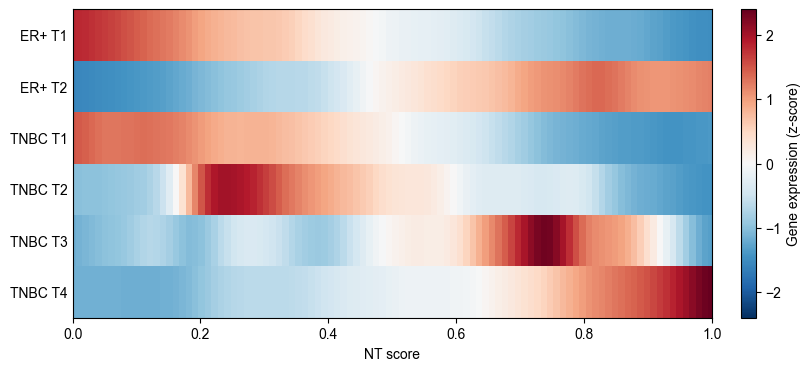

In [64]:
# Same NT-score normalization as your existing line plot.
x = df.index.to_numpy(dtype=float)
x = x / x.max()
expression = df.to_numpy().T  # rows = genes; columns = NT bins

# Bin boundaries preserve the numerical spacing of NT scores.
x_edges = np.r_[
    x[0] - (x[1] - x[0]) / 2,
    (x[:-1] + x[1:]) / 2,
    x[-1] + (x[-1] - x[-2]) / 2,
]
y_edges = np.arange(df.shape[1]+1)

# Shared, symmetric color scale centered at zero.
vmax = np.nanmax(np.abs(expression))
vmax = vmax if vmax > 0 else 1

fig, ax = plt.subplots(
    figsize=(8, 0.4 * df.shape[1] + 1.2),
    layout="constrained",
)

mesh = ax.pcolormesh(
    x_edges,
    y_edges,
    np.ma.masked_invalid(expression),
    cmap="RdBu_r",
    vmin=-vmax,
    vmax=vmax,
    shading="flat",
    rasterized=True,
)

ax.set_yticks(
    np.arange(df.shape[1]) + 0.5,
    labels=yticklabels,
)
ax.invert_yaxis()
ax.set_xlim(x.min(), x.max())
ax.set_xlabel("NT score")
ax.tick_params(axis="y", length=0)

fig.colorbar(mesh, ax=ax, label="Gene expression (z-score)", pad=0.03)
fig.savefig(f'{output_dir}/Fig3C.pdf', transparent=True)
fig.savefig(f'{output_dir}/Fig3C.svg', transparent=True)
fig.savefig(f'{output_dir}/Fig3C.png', dpi=150)

# GSEA analysis (Fig 3D)

In [65]:
settings = {
  "go_terms": {
    "shared_stromal": [
      'GO:0001525',   # angiogenesis                            NES: ER1=6.97, TNBC1=4.40
      'GO:0030198',   # extracellular matrix organization        NES: ER1=7.01, TNBC1=4.38
      # 'GO:0032963',   # collagen metabolic process               NES: ER1=4.79, TNBC1=4.02
      'GO:1901342',   # regulation of vasculature development    NES: ER1=6.10, TNBC1=4.04
      # 'GO:0043542',   # endothelial cell migration               NES: ER1=5.32, TNBC1=3.98
      # 'GO:0030199',   # collagen fibril organization             NES: ER1=4.84, TNBC1=3.96
      # 'GO:0006954',
    ],
    "er_stromal_specific": [
      'GO:0035886',   # vascular associated smooth muscle cell differentiation   NES=3.08
      'GO:0051152',   # positive regulation of smooth muscle cell differentiation NES=2.71
      'GO:0090026',   # positive regulation of monocyte chemotaxis               NES=2.63
      # 'GO:1903236',   # regulation of leukocyte tethering or rolling             NES=2.77
      # 'GO:0006910',   # phagocytosis, recognition                                NES=2.95
      # 'GO:0061042',   # vascular wound healing                                   NES=2.45
    ],
    "tnbc_stromal_specific": [
      'WP:WP3874',    # Canonical and non-canonical TGF-beta signaling   NES=2.60
      # 'GO:0006024',   # glycosaminoglycan biosynthetic process           NES=2.48
      # 'GO:0030201',   # heparan sulfate proteoglycan metabolic process   NES=2.35
      'GO:0030167',   # proteoglycan catabolic process                   NES=2.25
      'WP:WP4249',    # Hedgehog signaling                               NES=2.38
      # 'GO:0035313',   # wound healing, spreading of epidermal cells      NES=2.49
    ],
    "tnbc_immune_boundary_specific": [
      'GO:0070231',   # T cell apoptotic process                            NES=2.82
      # 'GO:0070229',   # negative regulation of lymphocyte apoptotic process NES=2.36
      # 'WP:WP4655',    # Cytosolic DNA sensing pathway                       NES=2.33
      # 'WP:WP4900',    # Purinergic signaling                                NES=2.11
      'GO:0043312',   # neutrophil degranulation                            NES=2.09
      'WP:WP4582',    # Cancer immunotherapy by CTLA4 blockade              NES=1.93
    ],
    "tnbc_invasive_boundary_specific": [
      'GO:0038128',   # ERBB2 signaling pathway                  NES=1.79
      'GO:2000736',   # regulation of stem cell differentiation  NES=1.59
      # 'GO:0019827',   # stem cell population maintenance         NES=1.43
      # 'GO:0072175',   # epithelial tube formation                NES=1.58
      # 'GO:0035148',   # tube formation                           NES=1.50
      'WP:WP391',     # Mitochondrial gene expression            NES=1.84
    ],
    "shared_tumor": [
      'GO:0006754',   # ATP biosynthetic process               NES: ER2=3.48, TNBC4=3.14
      'WP:WP623',     # Oxidative phosphorylation               NES: ER2=3.68, TNBC4=3.14
      'GO:0022900',   # electron transport chain                NES: ER2=3.06, TNBC4=3.29
      # 'GO:0009060',   # aerobic respiration                     NES: ER2=3.68, TNBC4=3.03
      # 'GO:0002181',   # cytoplasmic translation                 NES: ER2=2.87, TNBC4=3.62
      # 'GO:0051225',   # spindle assembly                        NES: ER2=3.10, TNBC4=2.45
    ],
    "er_tumor_specific": [
      'WP:WP183',     # Proteasome degradation                                     NES=3.06
      # 'GO:0043161',   # proteasome-mediated ubiquitin-dependent protein catabolism NES=2.96
      'GO:0065004',   # protein-DNA complex assembly                               NES=2.99
      # 'GO:0043484',   # regulation of RNA splicing                                 NES=3.02
      'GO:0034243',   # regulation of transcription elongation by RNA pol II       NES=2.78
      # 'GO:0045948',   # positive regulation of translational initiation            NES=2.78
    ],
    "tnbc_tumor_specific": [
      'WP:WP534',     # Glycolysis and gluconeogenesis                       NES=2.60
      # 'GO:0061621',   # canonical glycolysis                                 NES=2.14
      'GO:0000028',   # ribosomal small subunit assembly                     NES=1.90
      'GO:2000105',   # positive regulation of DNA-templated DNA replication NES=1.77
      # 'GO:0051255',   # spindle midzone assembly                             NES=2.18
      'WP:WP404',     # Nucleotide metabolism                                NES=2.21
    ]
  },
  "group_labels": {
    "shared_stromal": "Shared\nstromal",
    "er_stromal_specific": "ER stromal\nspecific",
    "tnbc_stromal_specific": "TNBC stromal\nspecific",
    "tnbc_immune_boundary_specific": "TNBC immune\nboundary\nspecific",
    "tnbc_invasive_boundary_specific": "TNBC invasive\nboundary\nspecific",
    "shared_tumor": "Shared\ntumor",
    "er_tumor_specific": "ER tumor\nspecific",
    "tnbc_tumor_specific": "TNBC tumor\nspecific"
  },
  "style": {
    "x_rotation": 45,
    "go_column_inches": 0.4725,
  }
}

In [66]:
plot_go_results(
    output_dir=output_dir,
    modules=[
        {'id': f'{cohort}{n}', 'label': f'{label} T{n}',
         'gsea_file': f'{cohort}_representative_expression_trajectory_{n}_GSEA_results.csv'}
        for cohort, label, numbers in [('ER', 'ER+', [1, 2]), ('TNBC', 'TNBC', [1, 2, 3, 4])]
        for n in numbers
    ],
    **settings)

Reading output/ER_representative_expression_trajectory_1_GSEA_results.csv...
Reading output/ER_representative_expression_trajectory_2_GSEA_results.csv...
Reading output/TNBC_representative_expression_trajectory_1_GSEA_results.csv...
Reading output/TNBC_representative_expression_trajectory_2_GSEA_results.csv...
Reading output/TNBC_representative_expression_trajectory_3_GSEA_results.csv...
Reading output/TNBC_representative_expression_trajectory_4_GSEA_results.csv...


# LR circle (Fig 3E)

In [67]:
patterns = [('ER','1'),('ER','2'),('TNBC','1'),('TNBC','2'),('TNBC','3'),('TNBC','4')]
lr_enrich_dict = {}
for pattern in patterns:
    lr_enrichment_df = pd.read_csv(f'{output_dir}/{pattern[0]}_representative_expression_trajectory_{pattern[1]}_LR_enrichment.csv', index_col=0)
    lr_enrich_dict[f'{pattern[0]}_T{pattern[1]}'] = lr_enrichment_df

In [68]:
fig, axes, multi_pathway_genes = plot_lr_circle_grid(
    lr_enrich_dict = lr_enrich_dict,
    top_n = 60,
    min_correlation = 0.5,
    use_absolute_correlation = False,
    max_p_value = 0.05,
    node_size = 20.0,
    ligand_color = "#4C78A8",
    receptor_color = "#F58518",
    min_edge_width = 0.5,
    max_edge_width = 3.0,
    show_cell_type = False,
    label_fontsize = 6.0,
    label_offset = 0.05,
    correlation_order = "descending",
    show_legend = True,
    ncols = 3,
    figsize = (20,15),
    sender_cell_type_column = "sender cell type",
    receiver_cell_type_column = "receiver cell type",
    ligand_column = "ligand",
    receptor_column = "receptor",
    ligand_correlation_column = "ligand_correlation",
    receptor_correlation_column = "receptor_correlation",
    importance_score_column = "importance_score",
    p_value_column = "p_value",
    interaction_id_column = "interaction_id",
    pathway_column = "pathway_name",
    color_edges_by_pathway = False,
    highlight_pathways = {
    # C0: Vascular endothelial adhesion
    'CDH5': 'C0',
    'ESAM': 'C0',
    'PECAM1': 'C0',

    # C1: ECM adhesion
    'COLLAGEN': 'C1',
    'LAMININ': 'C1',
    'THBS': 'C1',
    'PERIOSTIN': 'C1',
    'TENASCIN': 'C1',

    # C2: Epithelial adhesion and junctions
    'DESMOSOME': 'C2',
    'CLDN': 'C2',
    'CEACAM': 'C2',
    'CDH': 'C2',
    'CDH1': 'C2',
    'OCLN': 'C2',

    # C3: Chemokines
    'CCL': 'C3',
    'CXCL': 'C3',

    # C4: Chemerin
    'CHEMERIN': 'C4',

    # C5: EGF family
    'EGF': 'C5',

    # C6: TGF-beta family
    'TGFb': 'C6',

    # C7: Immune recognition and cytokine support
    'MHC-I': 'C7',
    'MHC-II': 'C7',
    'CD40': 'C7',
    'OX40': 'C7',
    'IL2': 'C7',

    # C8: PD-L1 checkpoint
    'PD-L1': 'C8',

    # C9: WNT/BMP/NOTCH families
    'WNT': 'C9',
    'ncWNT': 'C9',
    'BMP': 'C9',
    'NOTCH': 'C9',
},
)
fig.savefig(f'{output_dir}/Fig3E.pdf', transparent=True)
fig.savefig(f'{output_dir}/Fig3E.svg', transparent=True)
fig.savefig(f'{output_dir}/Fig3E.png', dpi=150)
plt.close(fig)

# session info

In [70]:
from session_info2 import session_info

session_info()

/tmp/ipykernel_1979283/869704283.py:3: RuntimeWarning: Failed to import dependencies for application/vnd.jupyter.widget-view+json representation. (ModuleNotFoundError: No module named 'ipywidgets')
  session_info()


Package,Version
pandas,2.2.1
numpy,1.26.4
matplotlib,3.10.8
gseapy,1.3.1
pygam,0.12.0
scipy,1.14.1
joblib,1.5.2
Component,Info
Python,"3.11.14 | packaged by conda-forge | (main, Oct 22 2025, 22:46:25) [GCC 14.3.0]"
OS,Linux-5.14.0-687.12.1.el9_8.x86_64-x86_64-with-glibc2.34
